# [8.6] AtP* from Scratch

**By the end of this notebook, you will have shown that AtP* repairs two concrete false negatives in vanilla attribution patching - saturated attention and cancellation - and that its ranking better predicts exhaustive causal interventions in a pinned 70M transformer.**

```python
EXERCISE_ID = "8_6_atp_star_from_scratch"
GT_TIER = "GT-0"
DIFFICULTY = 5
IMPORTANCE = 5
EXPECTED_RUNTIME = "2-3 hours; the cached CPU reference run takes about 90 seconds"
REQUIRES_GPU = False
```

## Core Question

**Can two forward caches and a small number of backward passes find the components exhaustive activation patching would rank highest - without silently missing a saturated query or a cancellation path?**

This section continues original ARENA's circuit workflow: define a crisp behavior, make predictions, intervene exactly, use a cheaper exploratory tool, and then grade the approximation against the causal experiment. AtP* is a **screening method**. Its top candidates still go back through activation patching before they become a circuit claim.

## Learning Objectives

1. Cache aligned clean and corrupt activations at named component sites.
2. Build an exhaustive activation-patching oracle with component batching.
3. Derive vanilla AtP as `(corrupt - clean) * clean_gradient`.
4. Repair saturated Q/K sites by recomputing the attention softmax exactly.
5. Repair direct/indirect gradient cancellation with GradDrop.
6. Distinguish node-level AtP* from an EAP-style immediate-edge baseline.
7. Evaluate rankings with recovery@k, rank correlation, joint faithfulness, runtime, and tensor storage.
8. Test the same logic on 96 named Q/K sites and 24 clean/corrupt examples in a pinned TransformerLens model.

## Cold Open - two components with a score of zero

The toy graph has eight named patch sites. Its attention head is nearly saturated on a signal value. Replacing the query flips attention and changes the metric by almost `-3`, but the clean softmax derivative is almost zero. A second component writes `x` directly and `-x^2 / 2` through another path. At `x=1`, those two gradients cancel exactly even though replacing `x` by zero changes the metric by `-0.5`.

Before running anything, write down two predictions:

1. Which component should the QK correction rescue?
2. Which dropped backward path should reveal the cancellation source?

The point is not that gradients are useless. The value site is linear and vanilla AtP gets it exactly. The point is that a cheap approximation needs targeted diagnostics.

In [1]:
import json
import math
import random
import sys
import time
from collections.abc import Mapping, Sequence
from dataclasses import asdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch as t
from torch import Tensor
from typing import Any, Literal

chapter = "chapter8_automated_circuits"
section = "part6_atp_star"
root_dir = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / chapter).exists())
exercises_dir = root_dir / chapter / "exercises"
assets_dir = root_dir / chapter / "instructions" / "assets"
for path in (root_dir, exercises_dir):
    if str(path) not in sys.path:
        sys.path.append(str(path))

import part6_atp_star.solutions as reference
import part6_atp_star.tests as tests
from part6_atp_star.solutions import (
    MethodEvaluation,
    TOY_CLEAN_VALUES,
    TOY_COMPONENT_INDEX,
    TOY_COMPONENTS,
    TOY_CORRUPT_VALUES,
    TOY_GRAD_PATHS,
    TOY_QK_COMPONENTS,
    ToyAtPStarModel,
    ToyRun,
    evaluate_toy_method,
    toy_site_tensor,
)

t.set_grad_enabled(True)
toy_model = ToyAtPStarModel()
clean_sites = toy_site_tensor(TOY_CLEAN_VALUES)
corrupt_sites = toy_site_tensor(TOY_CORRUPT_VALUES)
print(f"{len(TOY_COMPONENTS)} named sites; gradient controls: {TOY_GRAD_PATHS}")

8 named sites; gradient controls: ('attention', 'cancellation', 'linear')


### Exercise - cache the clean and corrupt worlds

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> Suggested time: 10 minutes
> ```

Implement `cache_clean_and_corrupt`. These two aligned runs are the reference points for every later approximation. Preserve the intermediate attention logits, pattern, branch outputs, and scalar metric; do not reduce the cache to the final answer.

<details><summary>Expected output</summary>

```text
All tests in `test_clean_corrupt_caches` passed!
clean metric = 2.900; corrupt metric = 0.000
clean attention pattern is approximately [1.0, 0.0]
```

</details>

<details><summary>Help - The model already returns its cache</summary>

Run both site tensors under `torch.no_grad()` and return the two `ToyRun` objects. Check the shapes before computing either endpoint.

</details>

<details><summary>Common bug</summary>

Detaching or copying only the metric discards `attention_pattern`, the activation whose gradient the QK correction needs.

</details>

<details><summary>Solution</summary>

```python
def cache_clean_and_corrupt(
    model: ToyAtPStarModel,
    clean_sites: Tensor,
    corrupt_sites: Tensor,
) -> tuple[ToyRun, ToyRun]:
    """Run both endpoints and retain every activation needed by the estimators."""

    if clean_sites.shape != corrupt_sites.shape:
        raise ValueError("Clean and corrupt site tensors must have identical shapes.")
    with t.no_grad():
        clean = model(clean_sites)
        corrupt = model(corrupt_sites)
    return clean, corrupt
```

</details>

In [2]:
def cache_clean_and_corrupt(
    model: ToyAtPStarModel,
    clean_sites: Tensor,
    corrupt_sites: Tensor,
) -> tuple[ToyRun, ToyRun]:
    """Run both endpoints and retain every activation needed by the estimators."""

    if clean_sites.shape != corrupt_sites.shape:
        raise ValueError("Clean and corrupt site tensors must have identical shapes.")
    with t.no_grad():
        clean = model(clean_sites)
        corrupt = model(corrupt_sites)
    return clean, corrupt

tests.test_clean_corrupt_caches(cache_clean_and_corrupt)
clean_run, corrupt_run = cache_clean_and_corrupt(toy_model, clean_sites, corrupt_sites)
print(f"clean metric = {clean_run.metric.item():.3f}; corrupt metric = {corrupt_run.metric.item():.3f}")
print("clean attention:", [round(x, 8) for x in clean_run.activations["attention_pattern"].tolist()])

All tests in `test_clean_corrupt_caches` passed!
clean metric = 2.900; corrupt metric = 0.000
clean attention: [0.99999998, 2e-08]


### Exercise - build the exhaustive oracle in component batches

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> Suggested time: 20 minutes
> ```

Implement `batched_exact_patch_effects`. For each named site, replace its clean value by the corrupt value and measure `patched_metric - clean_metric`. Evaluate several independent interventions in one tensor batch. This is the causal ground truth AtP* will be judged against.

<details><summary>Expected output</summary>

```text
All tests in `test_batched_exact_patch_effects` passed!
All tests in `test_batched_exact_patch_validation` passed!
Q effect = -3.000; cancel effect = -0.500; null effect = 0.000
```

</details>

<details><summary>Help - Rows are interventions; columns are sites</summary>

Repeat the clean vector once per component in the current chunk. Advanced-index the diagonal `(row, component_index)` entries with corrupt values, run the batch once, then map rows back to names.

</details>

<details><summary>Common bug</summary>

Patching all sites in a chunk into every row measures one joint intervention, not one independent intervention per row.

</details>

<details><summary>Solution</summary>

```python
def batched_exact_patch_effects(
    model: ToyAtPStarModel,
    clean_sites: Tensor,
    corrupt_sites: Tensor,
    *,
    component_batch_size: int = 4,
) -> dict[str, float]:
    """Exhaustively patch one site at a time, evaluating sites in vectorized batches."""

    if clean_sites.ndim != 1 or corrupt_sites.ndim != 1:
        raise ValueError("The exact toy oracle expects one clean/corrupt site vector.")
    if clean_sites.shape != corrupt_sites.shape:
        raise ValueError("Clean and corrupt site tensors must have identical shapes.")
    if component_batch_size <= 0:
        raise ValueError("component_batch_size must be positive.")

    with t.no_grad():
        clean_metric = float(model(clean_sites).metric)
        effects: dict[str, float] = {}
        for start in range(0, len(TOY_COMPONENTS), component_batch_size):
            indices = list(range(start, min(start + component_batch_size, len(TOY_COMPONENTS))))
            patched = clean_sites.repeat(len(indices), 1)
            rows = t.arange(len(indices), device=clean_sites.device)
            cols = t.tensor(indices, device=clean_sites.device)
            patched[rows, cols] = corrupt_sites[cols]
            patched_metrics = model(patched).metric
            for row, index in enumerate(indices):
                effects[TOY_COMPONENTS[index]] = float(patched_metrics[row] - clean_metric)
    return effects
```

</details>

In [3]:
def batched_exact_patch_effects(
    model: ToyAtPStarModel,
    clean_sites: Tensor,
    corrupt_sites: Tensor,
    *,
    component_batch_size: int = 4,
) -> dict[str, float]:
    """Exhaustively patch one site at a time, evaluating sites in vectorized batches."""

    if clean_sites.ndim != 1 or corrupt_sites.ndim != 1:
        raise ValueError("The exact toy oracle expects one clean/corrupt site vector.")
    if clean_sites.shape != corrupt_sites.shape:
        raise ValueError("Clean and corrupt site tensors must have identical shapes.")
    if component_batch_size <= 0:
        raise ValueError("component_batch_size must be positive.")

    with t.no_grad():
        clean_metric = float(model(clean_sites).metric)
        effects: dict[str, float] = {}
        for start in range(0, len(TOY_COMPONENTS), component_batch_size):
            indices = list(range(start, min(start + component_batch_size, len(TOY_COMPONENTS))))
            patched = clean_sites.repeat(len(indices), 1)
            rows = t.arange(len(indices), device=clean_sites.device)
            cols = t.tensor(indices, device=clean_sites.device)
            patched[rows, cols] = corrupt_sites[cols]
            patched_metrics = model(patched).metric
            for row, index in enumerate(indices):
                effects[TOY_COMPONENTS[index]] = float(patched_metrics[row] - clean_metric)
    return effects

tests.test_batched_exact_patch_effects(batched_exact_patch_effects)
tests.test_batched_exact_patch_validation(batched_exact_patch_effects)
exact_effects = batched_exact_patch_effects(toy_model, clean_sites, corrupt_sites)
print({name: round(value, 6) for name, value in exact_effects.items()})

All tests in `test_batched_exact_patch_effects` passed!
All tests in `test_batched_exact_patch_validation` passed!
{'L0H0.Q@dest': -3.0, 'L0H0.K@signal': -1.5, 'L0H0.K@decoy': -1.5, 'L0H0.V@signal': -2.0, 'L0H0.V@decoy': 0.0, 'L0M0.cancel_source': -0.5, 'L1M0.linear_source': -0.4, 'L1M1.null_source': 0.0}


### Exercise - compute vanilla attribution patching

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> Suggested time: 20 minutes
> ```

Implement `_toy_gradient_run` and `vanilla_attribution_patching`. Retain gradients on the site tensor and nonlinear intermediates, backpropagate the clean metric once, then compute the first-order estimate `(corrupt - clean) * grad`. Do not take absolute values yet: the sign is useful for debugging.

<details><summary>Expected output</summary>

```text
All tests in `test_vanilla_attribution_patching` passed!
Q: -0.0000016 despite exact -3.000
cancel source: 0.000 despite exact -0.500
V signal: -2.000, matching exact
```

</details>

<details><summary>Help - Make the site vector the leaf</summary>

Clone and detach the clean sites, call `requires_grad_(True)`, retain gradients on the intermediates needed by later exercises, and call `metric.backward()` exactly once.

</details>

<details><summary>Common bug</summary>

Using the corrupt gradient changes the Taylor expansion point. Summing gradients before multiplying by each site's own displacement also destroys component identity.

</details>

<details><summary>Solution</summary>

```python
def _toy_gradient_run(
    model: ToyAtPStarModel,
    clean_sites: Tensor,
    *,
    drop_grad_paths: Sequence[str] = (),
) -> tuple[ToyRun, Tensor]:
    sites = clean_sites.detach().clone().requires_grad_(True)
    run = model(sites, drop_grad_paths=drop_grad_paths)
    run.activations["attention_pattern"].retain_grad()
    run.activations["attention_logits"].retain_grad()
    run.activations["attention_output"].retain_grad()
    run.activations["direct_output"].retain_grad()
    run.activations["cancellation_input"].retain_grad()
    run.activations["linear_output"].retain_grad()
    run.metric.backward()
    if sites.grad is None:
        raise RuntimeError("The clean site gradient was not retained.")
    return run, sites.grad.detach().clone()


def vanilla_attribution_patching(
    model: ToyAtPStarModel,
    clean_sites: Tensor,
    corrupt_sites: Tensor,
) -> dict[str, float]:
    """Compute the first-order AtP estimate (corrupt-clean) dot grad at clean."""

    _, gradients = _toy_gradient_run(model, clean_sites)
    raw = (corrupt_sites - clean_sites) * gradients
    return {name: float(raw[index]) for index, name in enumerate(TOY_COMPONENTS)}
```

</details>

In [4]:
def _toy_gradient_run(
    model: ToyAtPStarModel,
    clean_sites: Tensor,
    *,
    drop_grad_paths: Sequence[str] = (),
) -> tuple[ToyRun, Tensor]:
    sites = clean_sites.detach().clone().requires_grad_(True)
    run = model(sites, drop_grad_paths=drop_grad_paths)
    run.activations["attention_pattern"].retain_grad()
    run.activations["attention_logits"].retain_grad()
    run.activations["attention_output"].retain_grad()
    run.activations["direct_output"].retain_grad()
    run.activations["cancellation_input"].retain_grad()
    run.activations["linear_output"].retain_grad()
    run.metric.backward()
    if sites.grad is None:
        raise RuntimeError("The clean site gradient was not retained.")
    return run, sites.grad.detach().clone()


def vanilla_attribution_patching(
    model: ToyAtPStarModel,
    clean_sites: Tensor,
    corrupt_sites: Tensor,
) -> dict[str, float]:
    """Compute the first-order AtP estimate (corrupt-clean) dot grad at clean."""

    _, gradients = _toy_gradient_run(model, clean_sites)
    raw = (corrupt_sites - clean_sites) * gradients
    return {name: float(raw[index]) for index, name in enumerate(TOY_COMPONENTS)}

tests.test_vanilla_attribution_patching(vanilla_attribution_patching)
vanilla_scores = vanilla_attribution_patching(toy_model, clean_sites, corrupt_sites)
print({name: f"{value:.7f}" for name, value in vanilla_scores.items()})

All tests in `test_vanilla_attribution_patching` passed!
{'L0H0.Q@dest': '-0.0000016', 'L0H0.K@signal': '-0.0000008', 'L0H0.K@decoy': '-0.0000008', 'L0H0.V@signal': '-2.0000000', 'L0H0.V@decoy': '0.0000000', 'L0M0.cancel_source': '-0.0000000', 'L1M0.linear_source': '-0.4000000', 'L1M1.null_source': '-0.0000000'}


### Exercise - repair saturated attention with the QK correction

> ```yaml
> Difficulty: 🔴🔴🔴🔴⚪
> Importance: 🔵🔵🔵🔵🔵
> Suggested time: 25 minutes
> ```

Implement `qk_softmax_correction`. Patch a query or key in activation space, recompute the attention softmax exactly, subtract the clean pattern, and dot that pattern change with `d metric / d pattern`. This is Equations 7 and 10 of the AtP* paper in a two-key graph.

Notice what remains approximate: only computation *after* the attention pattern. The saturated softmax itself is no longer linearized.

<details><summary>Expected output</summary>

```text
All tests in `test_qk_softmax_correction` passed!
All tests in `test_qk_softmax_correction_requires_gradient` passed!
corrected Q = -3.000; each corrected K = -1.500
```

</details>

<details><summary>Help - Three counterfactual patterns, one downstream gradient</summary>

Construct a query-patched pattern and one pattern for each key patch. The downstream dot product is `(patched_pattern - clean_pattern) * pattern_grad`, summed over source positions.

</details>

<details><summary>Common bug</summary>

Multiplying a patched logit difference by `d metric / d logit` still linearizes through softmax. AtP* needs the exact *probability* change.

</details>

<details><summary>Solution</summary>

```python
def qk_softmax_correction(
    run: ToyRun,
    clean_sites: Tensor,
    corrupt_sites: Tensor,
) -> dict[str, float]:
    """Recompute softmax after each Q/K patch, then linearize only downstream."""

    pattern = run.activations["attention_pattern"]
    pattern_grad = pattern.grad if pattern.is_leaf or pattern.retains_grad else None
    if pattern_grad is None:
        raise ValueError("attention_pattern.grad is required; call backward first.")
    if clean_sites.ndim != 1:
        raise ValueError("The toy QK correction expects one site vector.")

    q_i = TOY_COMPONENT_INDEX["L0H0.Q@dest"]
    ks_i = TOY_COMPONENT_INDEX["L0H0.K@signal"]
    kd_i = TOY_COMPONENT_INDEX["L0H0.K@decoy"]
    clean_q = clean_sites[q_i]
    clean_keys = clean_sites[[ks_i, kd_i]]
    clean_pattern = pattern.detach()

    query_pattern = (corrupt_sites[q_i] * clean_keys).softmax(dim=-1)
    signal_logits = t.stack((clean_q * corrupt_sites[ks_i], clean_q * clean_sites[kd_i]))
    decoy_logits = t.stack((clean_q * clean_sites[ks_i], clean_q * corrupt_sites[kd_i]))
    signal_pattern = signal_logits.softmax(dim=-1)
    decoy_pattern = decoy_logits.softmax(dim=-1)

    return {
        "L0H0.Q@dest": float(((query_pattern - clean_pattern) * pattern_grad).sum()),
        "L0H0.K@signal": float(((signal_pattern - clean_pattern) * pattern_grad).sum()),
        "L0H0.K@decoy": float(((decoy_pattern - clean_pattern) * pattern_grad).sum()),
    }
```

</details>

In [5]:
def qk_softmax_correction(
    run: ToyRun,
    clean_sites: Tensor,
    corrupt_sites: Tensor,
) -> dict[str, float]:
    """Recompute softmax after each Q/K patch, then linearize only downstream."""

    pattern = run.activations["attention_pattern"]
    pattern_grad = pattern.grad if pattern.is_leaf or pattern.retains_grad else None
    if pattern_grad is None:
        raise ValueError("attention_pattern.grad is required; call backward first.")
    if clean_sites.ndim != 1:
        raise ValueError("The toy QK correction expects one site vector.")

    q_i = TOY_COMPONENT_INDEX["L0H0.Q@dest"]
    ks_i = TOY_COMPONENT_INDEX["L0H0.K@signal"]
    kd_i = TOY_COMPONENT_INDEX["L0H0.K@decoy"]
    clean_q = clean_sites[q_i]
    clean_keys = clean_sites[[ks_i, kd_i]]
    clean_pattern = pattern.detach()

    query_pattern = (corrupt_sites[q_i] * clean_keys).softmax(dim=-1)
    signal_logits = t.stack((clean_q * corrupt_sites[ks_i], clean_q * clean_sites[kd_i]))
    decoy_logits = t.stack((clean_q * clean_sites[ks_i], clean_q * corrupt_sites[kd_i]))
    signal_pattern = signal_logits.softmax(dim=-1)
    decoy_pattern = decoy_logits.softmax(dim=-1)

    return {
        "L0H0.Q@dest": float(((query_pattern - clean_pattern) * pattern_grad).sum()),
        "L0H0.K@signal": float(((signal_pattern - clean_pattern) * pattern_grad).sum()),
        "L0H0.K@decoy": float(((decoy_pattern - clean_pattern) * pattern_grad).sum()),
    }

tests.test_qk_softmax_correction(qk_softmax_correction)
tests.test_qk_softmax_correction_requires_gradient(qk_softmax_correction)
gradient_run, _ = _toy_gradient_run(toy_model, clean_sites)
print(qk_softmax_correction(gradient_run, clean_sites, corrupt_sites))

All tests in `test_qk_softmax_correction` passed!
All tests in `test_qk_softmax_correction_requires_gradient` passed!
{'L0H0.Q@dest': -2.999999908620123, 'L0H0.K@signal': -1.4999999543100615, 'L0H0.K@decoy': -1.4999999543100615}


### Exercise - break cancellation with GradDrop

> ```yaml
> Difficulty: 🔴🔴🔴🔴🔴
> Importance: 🔵🔵🔵🔵🔵
> Suggested time: 30 minutes
> ```

Implement `atp_star_scores`. Repeat the backward pass once for each residual contribution, zeroing that contribution's gradient while preserving its forward value. Replace Q/K estimates with the corrected pattern-dot-gradient values for the same drop. Aggregate per-example magnitudes with the paper's `1 / (L - 1)` scaling.

For three toy paths, dropping `cancellation` removes the `-x` gradient and exposes the direct `+1` gradient. The other two drops still cancel to zero, so `(1 + 0 + 0) / 2 = 0.5`, exactly the intervention magnitude.

<details><summary>Expected output</summary>

```text
All tests in `test_atp_star_scores` passed!
All tests in `test_atp_star_grad_path_validation` passed!
AtP* exactly matches every toy intervention magnitude
drop cancellation -> cancel-source signed estimate = -1.000
```

</details>

<details><summary>Help - Forward values stay; only backward paths disappear</summary>

Call `_toy_gradient_run(..., drop_grad_paths=(path,))`. If dropping attention yields no pattern gradient, represent that missing gradient as zeros. Sum absolute per-drop estimates and divide by `len(paths) - 1`.

</details>

<details><summary>Common bug</summary>

Zeroing the forward activation is an ablation experiment, not GradDrop. It changes the clean behavior and invalidates the shared Taylor point.

</details>

<details><summary>Solution</summary>

```python
def atp_star_scores(
    model: ToyAtPStarModel,
    clean_sites: Tensor,
    corrupt_sites: Tensor,
    *,
    grad_paths: Sequence[str] = TOY_GRAD_PATHS,
) -> tuple[dict[str, float], dict[str, dict[str, float]]]:
    """Combine the paper's QK correction with layerwise GradDrop aggregation."""

    paths = tuple(grad_paths)
    if len(paths) < 2:
        raise ValueError("GradDrop needs at least two residual contribution paths.")
    if len(set(paths)) != len(paths):
        raise ValueError("GradDrop paths must be unique.")

    per_drop: dict[str, dict[str, float]] = {}
    for dropped in paths:
        run, gradients = _toy_gradient_run(model, clean_sites, drop_grad_paths=(dropped,))
        pattern = run.activations["attention_pattern"]
        if pattern.grad is None:
            pattern.grad = t.zeros_like(pattern)
        raw = (corrupt_sites - clean_sites) * gradients
        estimates = {
            name: float(raw[index]) for index, name in enumerate(TOY_COMPONENTS)
        }
        estimates.update(qk_softmax_correction(run, clean_sites, corrupt_sites))
        per_drop[dropped] = estimates

    denominator = len(paths) - 1
    scores = {
        name: sum(abs(per_drop[path][name]) for path in paths) / denominator
        for name in TOY_COMPONENTS
    }
    return scores, per_drop
```

</details>

In [6]:
def atp_star_scores(
    model: ToyAtPStarModel,
    clean_sites: Tensor,
    corrupt_sites: Tensor,
    *,
    grad_paths: Sequence[str] = TOY_GRAD_PATHS,
) -> tuple[dict[str, float], dict[str, dict[str, float]]]:
    """Combine the paper's QK correction with layerwise GradDrop aggregation."""

    paths = tuple(grad_paths)
    if len(paths) < 2:
        raise ValueError("GradDrop needs at least two residual contribution paths.")
    if len(set(paths)) != len(paths):
        raise ValueError("GradDrop paths must be unique.")

    per_drop: dict[str, dict[str, float]] = {}
    for dropped in paths:
        run, gradients = _toy_gradient_run(model, clean_sites, drop_grad_paths=(dropped,))
        pattern = run.activations["attention_pattern"]
        if pattern.grad is None:
            pattern.grad = t.zeros_like(pattern)
        raw = (corrupt_sites - clean_sites) * gradients
        estimates = {
            name: float(raw[index]) for index, name in enumerate(TOY_COMPONENTS)
        }
        estimates.update(qk_softmax_correction(run, clean_sites, corrupt_sites))
        per_drop[dropped] = estimates

    denominator = len(paths) - 1
    scores = {
        name: sum(abs(per_drop[path][name]) for path in paths) / denominator
        for name in TOY_COMPONENTS
    }
    return scores, per_drop

tests.test_atp_star_scores(atp_star_scores)
tests.test_atp_star_grad_path_validation(atp_star_scores)
atp_star_estimates, per_drop = atp_star_scores(toy_model, clean_sites, corrupt_sites)
print({name: round(value, 6) for name, value in atp_star_estimates.items()})
print("cancel source by dropped path:", {path: per_drop[path]["L0M0.cancel_source"] for path in TOY_GRAD_PATHS})

All tests in `test_atp_star_scores` passed!
All tests in `test_atp_star_grad_path_validation` passed!
{'L0H0.Q@dest': 3.0, 'L0H0.K@signal': 1.5, 'L0H0.K@decoy': 1.5, 'L0H0.V@signal': 2.0, 'L0H0.V@decoy': 0.0, 'L0M0.cancel_source': 0.5, 'L1M0.linear_source': 0.4, 'L1M1.null_source': 0.0}
cancel source by dropped path: {'attention': -0.0, 'cancellation': -1.0, 'linear': -0.0}


### Exercise - compare a distinct EAP-style edge baseline

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> Suggested time: 20 minutes
> ```

Implement `eap_style_edge_scores`. Attribute each immediate sender-to-receiver message, then sum absolute outgoing edge scores for a component. This avoids cancellation between the two outgoing edges of `cancel_source`, but it still linearizes at saturated attention logits. The comparison is useful because node AtP* and edge attribution answer different structural questions.

<details><summary>Expected output</summary>

```text
All tests in `test_eap_style_edge_scores` passed!
cancel source aggregated edge score = 1.000 (detected but overestimated)
query aggregated edge score < 0.000002 (still missed)
```

</details>

<details><summary>Help - Separate the two cancel-source receivers</summary>

Use the retained receiver gradients. For a Q-to-logit edge, the message displacement is `delta_q * clean_key`; for a value edge it is `clean_pattern * delta_value`.

</details>

<details><summary>Common bug</summary>

Using the total site gradient for both outgoing edges recreates the cancellation you are trying to diagnose.

</details>

<details><summary>Solution</summary>

```python
def eap_style_edge_scores(
    model: ToyAtPStarModel,
    clean_sites: Tensor,
    corrupt_sites: Tensor,
) -> tuple[dict[str, float], dict[str, float]]:
    """Score immediate graph edges, then aggregate outgoing edge magnitudes by site."""

    run, _ = _toy_gradient_run(model, clean_sites)
    activations = run.activations
    logits_grad = activations["attention_logits"].grad
    attention_output_grad = activations["attention_output"].grad
    direct_grad = activations["direct_output"].grad
    cancellation_grad = activations["cancellation_input"].grad
    linear_grad = activations["linear_output"].grad
    if any(value is None for value in (logits_grad, attention_output_grad, direct_grad, cancellation_grad, linear_grad)):
        raise RuntimeError("Required edge receiver gradients were not retained.")

    q_i, ks_i, kd_i, vs_i, vd_i, cancel_i, linear_i, _ = range(len(TOY_COMPONENTS))
    delta = corrupt_sites - clean_sites
    pattern = activations["attention_pattern"].detach()
    raw_edges = {
        "Q -> signal_logit": float(delta[q_i] * clean_sites[ks_i] * logits_grad[0]),
        "Q -> decoy_logit": float(delta[q_i] * clean_sites[kd_i] * logits_grad[1]),
        "K_signal -> signal_logit": float(clean_sites[q_i] * delta[ks_i] * logits_grad[0]),
        "K_decoy -> decoy_logit": float(clean_sites[q_i] * delta[kd_i] * logits_grad[1]),
        "V_signal -> attention_output": float(delta[vs_i] * pattern[0] * attention_output_grad),
        "V_decoy -> attention_output": float(delta[vd_i] * pattern[1] * attention_output_grad),
        "cancel_source -> direct_output": float(delta[cancel_i] * direct_grad),
        "cancel_source -> cancellation_output": float(delta[cancel_i] * cancellation_grad),
        "linear_source -> linear_output": float(0.4 * delta[linear_i] * linear_grad),
        "null_source -> metric": 0.0,
    }
    by_component = {
        "L0H0.Q@dest": abs(raw_edges["Q -> signal_logit"]) + abs(raw_edges["Q -> decoy_logit"]),
        "L0H0.K@signal": abs(raw_edges["K_signal -> signal_logit"]),
        "L0H0.K@decoy": abs(raw_edges["K_decoy -> decoy_logit"]),
        "L0H0.V@signal": abs(raw_edges["V_signal -> attention_output"]),
        "L0H0.V@decoy": abs(raw_edges["V_decoy -> attention_output"]),
        "L0M0.cancel_source": abs(raw_edges["cancel_source -> direct_output"])
        + abs(raw_edges["cancel_source -> cancellation_output"]),
        "L1M0.linear_source": abs(raw_edges["linear_source -> linear_output"]),
        "L1M1.null_source": 0.0,
    }
    return raw_edges, by_component
```

</details>

In [7]:
def eap_style_edge_scores(
    model: ToyAtPStarModel,
    clean_sites: Tensor,
    corrupt_sites: Tensor,
) -> tuple[dict[str, float], dict[str, float]]:
    """Score immediate graph edges, then aggregate outgoing edge magnitudes by site."""

    run, _ = _toy_gradient_run(model, clean_sites)
    activations = run.activations
    logits_grad = activations["attention_logits"].grad
    attention_output_grad = activations["attention_output"].grad
    direct_grad = activations["direct_output"].grad
    cancellation_grad = activations["cancellation_input"].grad
    linear_grad = activations["linear_output"].grad
    if any(value is None for value in (logits_grad, attention_output_grad, direct_grad, cancellation_grad, linear_grad)):
        raise RuntimeError("Required edge receiver gradients were not retained.")

    q_i, ks_i, kd_i, vs_i, vd_i, cancel_i, linear_i, _ = range(len(TOY_COMPONENTS))
    delta = corrupt_sites - clean_sites
    pattern = activations["attention_pattern"].detach()
    raw_edges = {
        "Q -> signal_logit": float(delta[q_i] * clean_sites[ks_i] * logits_grad[0]),
        "Q -> decoy_logit": float(delta[q_i] * clean_sites[kd_i] * logits_grad[1]),
        "K_signal -> signal_logit": float(clean_sites[q_i] * delta[ks_i] * logits_grad[0]),
        "K_decoy -> decoy_logit": float(clean_sites[q_i] * delta[kd_i] * logits_grad[1]),
        "V_signal -> attention_output": float(delta[vs_i] * pattern[0] * attention_output_grad),
        "V_decoy -> attention_output": float(delta[vd_i] * pattern[1] * attention_output_grad),
        "cancel_source -> direct_output": float(delta[cancel_i] * direct_grad),
        "cancel_source -> cancellation_output": float(delta[cancel_i] * cancellation_grad),
        "linear_source -> linear_output": float(0.4 * delta[linear_i] * linear_grad),
        "null_source -> metric": 0.0,
    }
    by_component = {
        "L0H0.Q@dest": abs(raw_edges["Q -> signal_logit"]) + abs(raw_edges["Q -> decoy_logit"]),
        "L0H0.K@signal": abs(raw_edges["K_signal -> signal_logit"]),
        "L0H0.K@decoy": abs(raw_edges["K_decoy -> decoy_logit"]),
        "L0H0.V@signal": abs(raw_edges["V_signal -> attention_output"]),
        "L0H0.V@decoy": abs(raw_edges["V_decoy -> attention_output"]),
        "L0M0.cancel_source": abs(raw_edges["cancel_source -> direct_output"])
        + abs(raw_edges["cancel_source -> cancellation_output"]),
        "L1M0.linear_source": abs(raw_edges["linear_source -> linear_output"]),
        "L1M1.null_source": 0.0,
    }
    return raw_edges, by_component

tests.test_eap_style_edge_scores(eap_style_edge_scores)
eap_edges, eap_scores = eap_style_edge_scores(toy_model, clean_sites, corrupt_sites)
print({name: round(value, 7) for name, value in eap_scores.items()})

All tests in `test_eap_style_edge_scores` passed!
{'L0H0.Q@dest': 1.6e-06, 'L0H0.K@signal': 8e-07, 'L0H0.K@decoy': 8e-07, 'L0H0.V@signal': 2.0, 'L0H0.V@decoy': 0.0, 'L0M0.cancel_source': 1.0, 'L1M0.linear_source': 0.4, 'L1M1.null_source': 0.0}


### Exercise - grade rankings and intervene on their prefixes

> ```yaml
> Difficulty: 🔴🔴🔴🔴⚪
> Importance: 🔵🔵🔵🔵🔵
> Suggested time: 30 minutes
> ```

Implement the evaluation stack: stable magnitude ranking, Spearman correlation with ties, cumulative exact-effect recovery@k, and joint top-k faithfulness. Recovery@k grades screening order against individual causal effects. Faithfulness actually patches the whole prefix and therefore exposes interaction, including overshoot and non-monotonicity.

<details><summary>Expected output</summary>

```text
All ranking and faithfulness tests passed!
Spearman: exact=1.000, AtP*=1.000, vanilla=0.627, EAP-style=0.563, random=-0.850
Recovery@4: exact/AtP*=0.899, vanilla=0.775, EAP-style=0.663, random=0.101
The exact top-1 faithfulness is 1.034 and the curve is not monotone
```

</details>

<details><summary>Help - Do not confuse effect mass with joint behavior</summary>

For recovery, sum absolute exact singleton effects selected by the proposed order. For faithfulness, patch selected sites together and divide the joint effect by the all-sites corrupt effect.

</details>

<details><summary>Common bug</summary>

Summing selected singleton effects and calling it faithfulness assumes additivity, exactly the assumption this toy graph violates.

</details>

<details><summary>Solution</summary>

```python
def rank_components(scores: Mapping[str, float]) -> tuple[str, ...]:
    """Rank named components by descending magnitude with a stable name tie-break."""

    if set(scores) != set(TOY_COMPONENTS):
        raise ValueError("Scores must contain every toy component exactly once.")
    if not all(math.isfinite(float(value)) for value in scores.values()):
        raise ValueError("Scores must be finite.")
    return tuple(sorted(TOY_COMPONENTS, key=lambda name: (-abs(float(scores[name])), name)))


def _average_ranks(values: Sequence[float]) -> Tensor:
    values_tensor = t.tensor(values, dtype=t.float64)
    result = t.empty_like(values_tensor)
    for value in values_tensor.unique():
        positions = (values_tensor == value).nonzero(as_tuple=False).flatten()
        less = int((values_tensor < value).sum())
        result[positions] = less + (len(positions) - 1) / 2
    return result


def spearman_rank_correlation(
    reference: Mapping[str, float],
    estimate: Mapping[str, float],
) -> float:
    """Compute Spearman correlation over component magnitudes, including ties."""

    if set(reference) != set(estimate):
        raise ValueError("Reference and estimate must contain the same names.")
    names = tuple(sorted(reference))
    x = _average_ranks([abs(float(reference[name])) for name in names])
    y = _average_ranks([abs(float(estimate[name])) for name in names])
    x = x - x.mean()
    y = y - y.mean()
    denominator = x.norm() * y.norm()
    return 0.0 if float(denominator) == 0.0 else float((x @ y) / denominator)


def recovery_at_k(
    exact_effects: Mapping[str, float],
    ranking: Sequence[str],
) -> tuple[float, ...]:
    """Return cumulative exact-effect mass captured by a proposed ranking."""

    if set(ranking) != set(exact_effects) or len(ranking) != len(exact_effects):
        raise ValueError("ranking must be a permutation of exact-effect names.")
    total = sum(abs(float(value)) for value in exact_effects.values())
    if total <= 0:
        raise ValueError("Exact effect mass must be positive.")
    cumulative = 0.0
    result = []
    for name in ranking:
        cumulative += abs(float(exact_effects[name]))
        result.append(cumulative / total)
    return tuple(result)


def topk_faithfulness_curve(
    model: ToyAtPStarModel,
    clean_sites: Tensor,
    corrupt_sites: Tensor,
    ranking: Sequence[str],
) -> tuple[float, ...]:
    """Patch the top-k sites jointly and normalize their effect by full corruption."""

    if tuple(sorted(ranking)) != tuple(sorted(TOY_COMPONENTS)):
        raise ValueError("ranking must contain every toy component exactly once.")
    with t.no_grad():
        clean_metric = model(clean_sites).metric
        full_effect = (model(corrupt_sites).metric - clean_metric).abs()
        if float(full_effect) == 0.0:
            raise ValueError("Full corruption must change the metric.")
        patched = clean_sites.clone()
        curve = []
        for name in ranking:
            index = TOY_COMPONENT_INDEX[name]
            patched[index] = corrupt_sites[index]
            curve.append(float((model(patched).metric - clean_metric).abs() / full_effect))
    return tuple(curve)
```

</details>

In [8]:
def rank_components(scores: Mapping[str, float]) -> tuple[str, ...]:
    """Rank named components by descending magnitude with a stable name tie-break."""

    if set(scores) != set(TOY_COMPONENTS):
        raise ValueError("Scores must contain every toy component exactly once.")
    if not all(math.isfinite(float(value)) for value in scores.values()):
        raise ValueError("Scores must be finite.")
    return tuple(sorted(TOY_COMPONENTS, key=lambda name: (-abs(float(scores[name])), name)))


def _average_ranks(values: Sequence[float]) -> Tensor:
    values_tensor = t.tensor(values, dtype=t.float64)
    result = t.empty_like(values_tensor)
    for value in values_tensor.unique():
        positions = (values_tensor == value).nonzero(as_tuple=False).flatten()
        less = int((values_tensor < value).sum())
        result[positions] = less + (len(positions) - 1) / 2
    return result


def spearman_rank_correlation(
    reference: Mapping[str, float],
    estimate: Mapping[str, float],
) -> float:
    """Compute Spearman correlation over component magnitudes, including ties."""

    if set(reference) != set(estimate):
        raise ValueError("Reference and estimate must contain the same names.")
    names = tuple(sorted(reference))
    x = _average_ranks([abs(float(reference[name])) for name in names])
    y = _average_ranks([abs(float(estimate[name])) for name in names])
    x = x - x.mean()
    y = y - y.mean()
    denominator = x.norm() * y.norm()
    return 0.0 if float(denominator) == 0.0 else float((x @ y) / denominator)


def recovery_at_k(
    exact_effects: Mapping[str, float],
    ranking: Sequence[str],
) -> tuple[float, ...]:
    """Return cumulative exact-effect mass captured by a proposed ranking."""

    if set(ranking) != set(exact_effects) or len(ranking) != len(exact_effects):
        raise ValueError("ranking must be a permutation of exact-effect names.")
    total = sum(abs(float(value)) for value in exact_effects.values())
    if total <= 0:
        raise ValueError("Exact effect mass must be positive.")
    cumulative = 0.0
    result = []
    for name in ranking:
        cumulative += abs(float(exact_effects[name]))
        result.append(cumulative / total)
    return tuple(result)


def topk_faithfulness_curve(
    model: ToyAtPStarModel,
    clean_sites: Tensor,
    corrupt_sites: Tensor,
    ranking: Sequence[str],
) -> tuple[float, ...]:
    """Patch the top-k sites jointly and normalize their effect by full corruption."""

    if tuple(sorted(ranking)) != tuple(sorted(TOY_COMPONENTS)):
        raise ValueError("ranking must contain every toy component exactly once.")
    with t.no_grad():
        clean_metric = model(clean_sites).metric
        full_effect = (model(corrupt_sites).metric - clean_metric).abs()
        if float(full_effect) == 0.0:
            raise ValueError("Full corruption must change the metric.")
        patched = clean_sites.clone()
        curve = []
        for name in ranking:
            index = TOY_COMPONENT_INDEX[name]
            patched[index] = corrupt_sites[index]
            curve.append(float((model(patched).metric - clean_metric).abs() / full_effect))
    return tuple(curve)

tests.test_rank_components(rank_components)
tests.test_spearman_rank_correlation(spearman_rank_correlation)
tests.test_recovery_at_k(recovery_at_k)
tests.test_topk_faithfulness_is_not_additive(topk_faithfulness_curve)

All tests in `test_rank_components` passed!
All tests in `test_spearman_rank_correlation` passed!
All tests in `test_recovery_at_k` passed!
All tests in `test_topk_faithfulness_is_not_additive` passed!


## Signature Result - exact effects, recovered ranking, and causal prefixes

The next cell recomputes every method from your functions. The left panel makes both false negatives legible. The middle panels answer whether the ranking spends a limited verification budget well and whether its selected prefix actually changes behavior. The final panel shows the measured speed/cost tradeoff on this tiny graph; use the pass counts, not microsecond differences, when reasoning about scale.

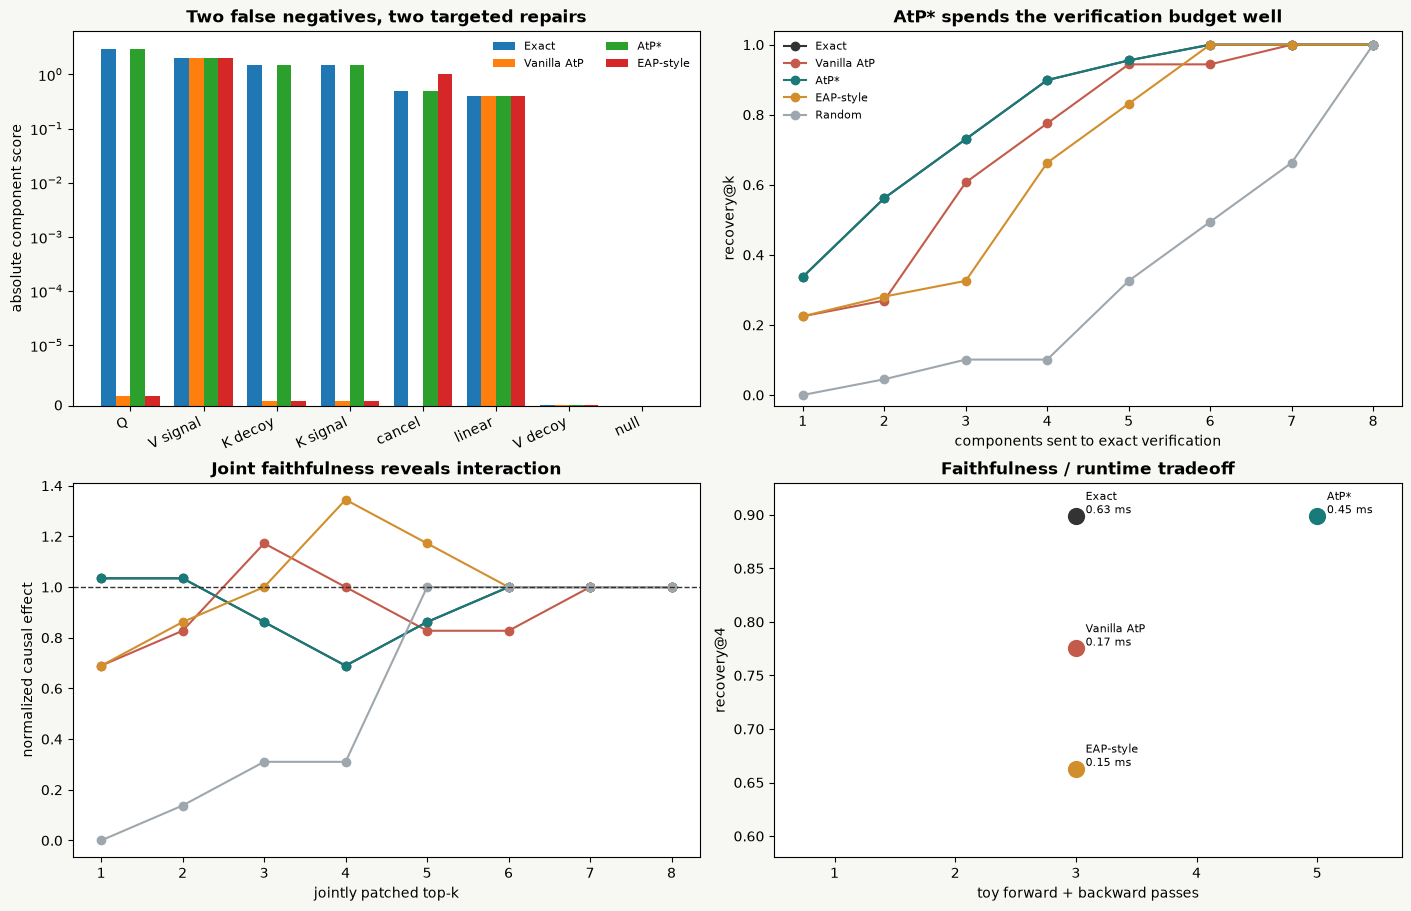

Spearman: {'Exact': 1.0, 'Vanilla AtP': 0.627, 'AtP*': 1.0, 'EAP-style': 0.563, 'Random': -0.85}
Recovery@4: {'Exact': 0.899, 'Vanilla AtP': 0.775, 'AtP*': 0.899, 'EAP-style': 0.663, 'Random': 0.101}


In [9]:
def timed(fn):
    start = time.perf_counter()
    value = fn()
    return value, (time.perf_counter() - start) * 1000


(exact_effects, exact_ms) = timed(lambda: batched_exact_patch_effects(toy_model, clean_sites, corrupt_sites, component_batch_size=4))
(vanilla_scores, vanilla_ms) = timed(lambda: vanilla_attribution_patching(toy_model, clean_sites, corrupt_sites))
((atp_star_estimates, per_drop), atp_star_ms) = timed(lambda: atp_star_scores(toy_model, clean_sites, corrupt_sites))
((eap_edges, eap_scores), eap_ms) = timed(lambda: eap_style_edge_scores(toy_model, clean_sites, corrupt_sites))
random_scores = {name: float(i) for i, name in enumerate(TOY_COMPONENTS)}

method_scores = {
    "Exact": exact_effects,
    "Vanilla AtP": vanilla_scores,
    "AtP*": atp_star_estimates,
    "EAP-style": eap_scores,
    "Random": random_scores,
}
method_times = {"Exact": exact_ms, "Vanilla AtP": vanilla_ms, "AtP*": atp_star_ms, "EAP-style": eap_ms, "Random": 0.0}
rankings = {name: rank_components(scores) for name, scores in method_scores.items()}
recoveries = {name: recovery_at_k(exact_effects, ranking) for name, ranking in rankings.items()}
faithfulness = {name: topk_faithfulness_curve(toy_model, clean_sites, corrupt_sites, ranking) for name, ranking in rankings.items()}
spearman = {name: spearman_rank_correlation(exact_effects, scores) for name, scores in method_scores.items()}

short = {
    "L0H0.Q@dest": "Q",
    "L0H0.K@signal": "K signal",
    "L0H0.K@decoy": "K decoy",
    "L0H0.V@signal": "V signal",
    "L0H0.V@decoy": "V decoy",
    "L0M0.cancel_source": "cancel",
    "L1M0.linear_source": "linear",
    "L1M1.null_source": "null",
}
order = rankings["Exact"]
x = np.arange(len(order))
width = 0.2
fig, axes = plt.subplots(2, 2, figsize=(14, 9), constrained_layout=True)
fig.patch.set_facecolor("#f7f7f4")

for offset, method in zip((-1.5, -0.5, 0.5, 1.5), ("Exact", "Vanilla AtP", "AtP*", "EAP-style"), strict=True):
    axes[0, 0].bar(x + offset * width, [abs(method_scores[method][name]) for name in order], width, label=method)
axes[0, 0].set_yscale("symlog", linthresh=1e-5)
axes[0, 0].set_xticks(x, [short[name] for name in order], rotation=25, ha="right")
axes[0, 0].set_ylabel("absolute component score")
axes[0, 0].set_title("Two false negatives, two targeted repairs", fontweight="bold")
axes[0, 0].legend(frameon=False, ncols=2, fontsize=8)

palette = {"Exact": "#333333", "Vanilla AtP": "#c45a4a", "AtP*": "#187a79", "EAP-style": "#d28e2c", "Random": "#9ea7ad"}
for method in method_scores:
    axes[0, 1].plot(range(1, 9), recoveries[method], marker="o", label=method, color=palette[method])
axes[0, 1].set(xlabel="components sent to exact verification", ylabel="recovery@k", ylim=(-0.03, 1.04))
axes[0, 1].set_title("AtP* spends the verification budget well", fontweight="bold")
axes[0, 1].legend(frameon=False, fontsize=8)

for method in method_scores:
    axes[1, 0].plot(range(1, 9), faithfulness[method], marker="o", label=method, color=palette[method])
axes[1, 0].axhline(1.0, color="#333333", linestyle="--", linewidth=1)
axes[1, 0].set(xlabel="jointly patched top-k", ylabel="normalized causal effect")
axes[1, 0].set_title("Joint faithfulness reveals interaction", fontweight="bold")

costs = {"Exact": (3, 0), "Vanilla AtP": (2, 1), "AtP*": (2, 3), "EAP-style": (2, 1)}
for method, (forward, backward) in costs.items():
    axes[1, 1].scatter(forward + backward, recoveries[method][3], s=130, color=palette[method])
    axes[1, 1].annotate(f"{method}\n{method_times[method]:.2f} ms", (forward + backward, recoveries[method][3]), xytext=(7, 2), textcoords="offset points", fontsize=8)
axes[1, 1].set(xlabel="toy forward + backward passes", ylabel="recovery@4", xlim=(0.5, 5.7), ylim=(0.58, 0.93))
axes[1, 1].set_title("Faithfulness / runtime tradeoff", fontweight="bold")

toy_asset = assets_dir / "atp_star_toy_signature.png"
fig.savefig(toy_asset, dpi=180, bbox_inches="tight", facecolor=fig.get_facecolor())
plt.show()

print("Spearman:", {name: round(value, 3) for name, value in spearman.items()})
print("Recovery@4:", {name: round(values[3], 3) for name, values in recoveries.items()})

<details><summary>Interpretation - what AtP* fixed, and what it did not</summary>

- **QK fix:** the query's true magnitude is `3.0`; vanilla AtP and EAP-style local gradients assign about `1.6e-6`. Exact softmax recomputation restores the full pattern change.
- **GradDrop:** the cancel source's true magnitude is `0.5`; its full clean gradient is exactly zero. Dropping the nonlinear residual contribution exposes a signed estimate of `-1`, and the paper's aggregation returns `0.5`.
- **EAP-style edge attribution:** separating outgoing edges detects the cancellation source, but overestimates it as `1.0` and still misses saturated Q/K. Edge scores answer a different structural question from node scores.
- **Joint faithfulness:** the best singleton overshoots the full corrupt effect and adding another important component can reduce the curve. A good singleton ranking does not make a nonlinear circuit additive.
- **Cost:** exhaustive patching scales with component count; AtP* scales with model depth plus inexpensive QK recomputation. AtP* is still more expensive than vanilla AtP, so use it where false negatives matter.

</details>

### Exercise - define the real task metric and named Q/K sites

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> Suggested time: 20 minutes
> ```

Implement `per_prompt_logit_diff`, `real_component_names`, and `parse_real_component`. The real study has 24 equal-length plural/singular pairs across three answer-token families. Each of six layers and eight heads contributes one final-position query and one final-position key site: 96 candidates total.

<details><summary>Expected output</summary>

```text
All tests in `test_per_prompt_logit_diff` passed!
All tests in `test_real_component_names_and_parser` passed!
24 examples; 96 named Q/K components; sequence length 3
```

</details>

<details><summary>Help - Keep task and component axes explicit</summary>

Gather positive and negative logits using one token id per batch row. Generate names in layer-major, head-major, Q-then-K order; reject malformed names rather than guessing.

</details>

<details><summary>Common bug</summary>

Averaging logits before applying per-example token ids mixes the `are/is`, `have/has`, and `run/runs` tasks.

</details>

<details><summary>Solution</summary>

```python
def per_prompt_logit_diff(logits: Tensor, positive_ids: Tensor, negative_ids: Tensor) -> Tensor:
    """Return positive-minus-negative final-token logits for each prompt."""

    if logits.ndim != 3 or positive_ids.ndim != 1 or negative_ids.ndim != 1:
        raise ValueError("Expected logits [batch, position, vocab] and token ids [batch].")
    if logits.shape[0] != positive_ids.shape[0] or positive_ids.shape != negative_ids.shape:
        raise ValueError("Batch dimensions must match.")
    final = logits[:, -1]
    rows = t.arange(final.shape[0], device=final.device)
    return final[rows, positive_ids] - final[rows, negative_ids]


def real_component_names(n_layers: int, n_heads: int) -> tuple[str, ...]:
    return tuple(
        f"L{layer}H{head}.{kind}@end"
        for layer in range(n_layers)
        for head in range(n_heads)
        for kind in ("Q", "K")
    )


def parse_real_component(name: str) -> tuple[int, int, Literal["Q", "K"]]:
    try:
        prefix, suffix = name.split(".")
        layer_text, head_text = prefix[1:].split("H")
        kind, position = suffix.split("@")
        if position != "end" or kind not in {"Q", "K"}:
            raise ValueError
        return int(layer_text), int(head_text), kind  # type: ignore[return-value]
    except (ValueError, IndexError) as exc:
        raise ValueError(f"Invalid component name: {name!r}") from exc
```

</details>

In [10]:
def per_prompt_logit_diff(logits: Tensor, positive_ids: Tensor, negative_ids: Tensor) -> Tensor:
    """Return positive-minus-negative final-token logits for each prompt."""

    if logits.ndim != 3 or positive_ids.ndim != 1 or negative_ids.ndim != 1:
        raise ValueError("Expected logits [batch, position, vocab] and token ids [batch].")
    if logits.shape[0] != positive_ids.shape[0] or positive_ids.shape != negative_ids.shape:
        raise ValueError("Batch dimensions must match.")
    final = logits[:, -1]
    rows = t.arange(final.shape[0], device=final.device)
    return final[rows, positive_ids] - final[rows, negative_ids]


def real_component_names(n_layers: int, n_heads: int) -> tuple[str, ...]:
    return tuple(
        f"L{layer}H{head}.{kind}@end"
        for layer in range(n_layers)
        for head in range(n_heads)
        for kind in ("Q", "K")
    )


def parse_real_component(name: str) -> tuple[int, int, Literal["Q", "K"]]:
    try:
        prefix, suffix = name.split(".")
        layer_text, head_text = prefix[1:].split("H")
        kind, position = suffix.split("@")
        if position != "end" or kind not in {"Q", "K"}:
            raise ValueError
        return int(layer_text), int(head_text), kind  # type: ignore[return-value]
    except (ValueError, IndexError) as exc:
        raise ValueError(f"Invalid component name: {name!r}") from exc

tests.test_per_prompt_logit_diff(per_prompt_logit_diff)
tests.test_real_component_names_and_parser(real_component_names, parse_real_component)
print(f"{len(reference.build_grammar_pairs())} examples; {len(real_component_names(6, 8))} named Q/K components")

All tests in `test_per_prompt_logit_diff` passed!
All tests in `test_real_component_names_and_parser` passed!
24 examples; 96 named Q/K components


## Real-model path - retain paths before ranking components

The next cells expose the same computation on 96 final-position rotary Q/K sites
in pinned Pythia-70M. Caching and batching are provided below; read their token
indices before implementing the real gradients. All scores and intervention
controls are computed here from the learner functions.

We freeze model parameters to avoid unnecessary gradients. That does **not** mean
intermediate activations should be detached: cutting every Q/K tensor silently
removes paths through later attention layers. GradDrop removes only one selected
layer's residual contributions per backward pass.

The paper's [GradDrop definition](https://arxiv.org/html/2403.00745v1#S3.SS1.SSS2)
zeros the selected residual contribution's gradient and scales the sum of absolute
estimates by `1 / (L - 1)`. This implementation reruns the clean forward pass for
each dropped layer; the paper can reuse it. Timings below include that overhead.

In [11]:
load_pinned_pythia70m = reference.load_pinned_pythia70m
prepare_grammar_task = reference.prepare_grammar_task
PYTHIA_MODEL_NAME = reference.PYTHIA_MODEL_NAME
PYTHIA_HF_ID = reference.PYTHIA_HF_ID
PYTHIA_REVISION = reference.PYTHIA_REVISION

def _q_hook_name(layer: int) -> str:
    return f"blocks.{layer}.attn.hook_rot_q"


def _k_hook_name(layer: int) -> str:
    return f"blocks.{layer}.attn.hook_rot_k"


def _pattern_hook_name(layer: int) -> str:
    return f"blocks.{layer}.attn.hook_pattern"


def cache_real_qk(model: Any, task: Mapping[str, Any]) -> dict[str, Any]:
    """Cache clean/corrupt rotary Q/K and clean patterns for every layer."""

    names = {
        name
        for layer in range(model.cfg.n_layers)
        for name in (_q_hook_name(layer), _k_hook_name(layer), _pattern_hook_name(layer))
    }
    with t.inference_mode():
        clean_logits, clean_cache = model.run_with_cache(
            task["clean_tokens"], names_filter=lambda name: name in names
        )
        corrupt_logits, corrupt_cache = model.run_with_cache(
            task["corrupt_tokens"], names_filter=lambda name: name in names
        )
    clean_metric = per_prompt_logit_diff(
        clean_logits, task["positive_ids"], task["negative_ids"]
    )
    corrupt_metric = per_prompt_logit_diff(
        corrupt_logits, task["positive_ids"], task["negative_ids"]
    )
    return {
        "clean_cache": clean_cache,
        "corrupt_cache": corrupt_cache,
        "clean_metric": clean_metric,
        "corrupt_metric": corrupt_metric,
    }


def _patch_component_chunk_hooks(
    components: Sequence[str],
    corrupt_cache: Mapping[str, Tensor],
    *,
    examples_per_component: int,
) -> list[tuple[str, Any]]:
    hooks = []
    for layer in sorted({parse_real_component(name)[0] for name in components}):
        for kind, hook_name in (("Q", _q_hook_name(layer)), ("K", _k_hook_name(layer))):
            selected = [
                (index, parse_real_component(name)[1])
                for index, name in enumerate(components)
                if parse_real_component(name)[0] == layer and parse_real_component(name)[2] == kind
            ]
            if not selected:
                continue

            def patch_hook(activation: Tensor, hook: Any, selected=selected, hook_name=hook_name):
                patched = activation.clone()
                source = corrupt_cache[hook_name]
                for component_index, head in selected:
                    rows = slice(
                        component_index * examples_per_component,
                        (component_index + 1) * examples_per_component,
                    )
                    patched[rows, -1, head] = source[:, -1, head]
                return patched

            hooks.append((hook_name, patch_hook))
    return hooks


def exact_real_patch_effects(
    model: Any,
    task: Mapping[str, Any],
    cache: Mapping[str, Any],
    *,
    component_batch_size: int = 8,
) -> dict[str, float]:
    """Exhaustively patch every final-position Q/K site, batching components."""

    if component_batch_size <= 0:
        raise ValueError("component_batch_size must be positive.")
    names = real_component_names(model.cfg.n_layers, model.cfg.n_heads)
    batch = task["clean_tokens"].shape[0]
    effects: dict[str, float] = {}
    with t.inference_mode():
        for start in range(0, len(names), component_batch_size):
            chunk = names[start : start + component_batch_size]
            repeated_tokens = task["clean_tokens"].repeat(len(chunk), 1)
            repeated_positive = task["positive_ids"].repeat(len(chunk))
            repeated_negative = task["negative_ids"].repeat(len(chunk))
            hooks = _patch_component_chunk_hooks(
                chunk, cache["corrupt_cache"], examples_per_component=batch
            )
            logits = model.run_with_hooks(repeated_tokens, fwd_hooks=hooks)
            metrics = per_prompt_logit_diff(logits, repeated_positive, repeated_negative)
            deltas = metrics.reshape(len(chunk), batch) - cache["clean_metric"].unsqueeze(0)
            for index, name in enumerate(chunk):
                effects[name] = float(deltas[index].abs().mean())
    return effects

### Exercise - retain node gradients and drop exactly one layer

> Difficulty: 4/5 | Importance: 5/5 | Suggested time: 25 minutes

Implement vanilla node attribution for rotary queries and keys, then obtain
attention-pattern gradients with one layer's attention and MLP residual outputs
detached. Preserve all other edges in the graph. In the test chain, the first
query has derivative `2 * (1+3) * (1+5) = 48`; dropping the last layer changes the
first pattern derivative to `2 * (1+3) = 8`.

<details><summary>Expected output</summary>

The independent test below prints a success message. A detached intermediate
activation must fail the cross-layer derivative check.

</details>

<details><summary>Help</summary>

Follow tensor shapes explicitly. `requires_grad_(True)` starts a graph for frozen
inputs; `retain_grad()` stores intermediate derivatives without cutting existing
paths. Only the selected GradDrop residual contributions should detach.

</details>

<details><summary>Solution</summary>

```python
def vanilla_real_atp_scores(
    model: Any,
    task: Mapping[str, Any],
    cache: Mapping[str, Any],
) -> dict[str, float]:
    """Compute node-level AtP for all final-position rotary Q/K sites in one backward pass."""

    leaves: dict[str, Tensor] = {}
    hooks = []
    for layer in range(model.cfg.n_layers):
        for hook_name in (_q_hook_name(layer), _k_hook_name(layer)):
            def leaf_hook(activation: Tensor, hook: Any, hook_name=hook_name):
                # Keep the path through later attention layers. Detaching every
                # cached node would measure a different, truncated graph.
                activation.requires_grad_(True)
                activation.retain_grad()
                leaves[hook_name] = activation
                return activation

            hooks.append((hook_name, leaf_hook))
    logits = model.run_with_hooks(task["clean_tokens"], fwd_hooks=hooks)
    per_prompt_logit_diff(logits, task["positive_ids"], task["negative_ids"]).sum().backward()

    scores = {}
    for name in real_component_names(model.cfg.n_layers, model.cfg.n_heads):
        layer, head, kind = parse_real_component(name)
        hook_name = _q_hook_name(layer) if kind == "Q" else _k_hook_name(layer)
        leaf = leaves[hook_name]
        if leaf.grad is None:
            raise RuntimeError(f"No gradient retained for {hook_name}.")
        delta = cache["corrupt_cache"][hook_name][:, -1, head] - cache["clean_cache"][hook_name][:, -1, head]
        estimate = (delta * leaf.grad[:, -1, head]).sum(dim=-1)
        scores[name] = float(estimate.abs().mean())
    return scores


def _pattern_gradients(
    model: Any,
    task: Mapping[str, Any],
    *,
    dropped_layer: int,
    positive_ids: Tensor,
    negative_ids: Tensor,
) -> dict[str, Tensor]:
    leaves: dict[str, Tensor] = {}
    hooks = []
    for layer in range(model.cfg.n_layers):
        hook_name = _pattern_hook_name(layer)

        def pattern_leaf(activation: Tensor, hook: Any, hook_name=hook_name):
            activation.requires_grad_(True)
            activation.retain_grad()
            leaves[hook_name] = activation
            return activation

        hooks.append((hook_name, pattern_leaf))

    for hook_name in (
        f"blocks.{dropped_layer}.hook_attn_out",
        f"blocks.{dropped_layer}.hook_mlp_out",
    ):
        hooks.append((hook_name, lambda activation, hook: activation.detach()))

    logits = model.run_with_hooks(task["clean_tokens"], fwd_hooks=hooks)
    per_prompt_logit_diff(logits, positive_ids, negative_ids).sum().backward()
    gradients = {}
    for name, leaf in leaves.items():
        if leaf.grad is None:
            gradients[name] = t.zeros_like(leaf)
        else:
            gradients[name] = leaf.grad.detach().clone()
    return gradients
```

</details>

<details><summary>Interpretation</summary>

An approximation can correlate with exact patching despite a wrong derivative.
The hand-computable tests establish the operation before the real experiment
measures whether its ranking is useful.

</details>

In [12]:
def vanilla_real_atp_scores(
    model: Any,
    task: Mapping[str, Any],
    cache: Mapping[str, Any],
) -> dict[str, float]:
    """Compute node-level AtP for all final-position rotary Q/K sites in one backward pass."""

    leaves: dict[str, Tensor] = {}
    hooks = []
    for layer in range(model.cfg.n_layers):
        for hook_name in (_q_hook_name(layer), _k_hook_name(layer)):
            def leaf_hook(activation: Tensor, hook: Any, hook_name=hook_name):
                # Keep the path through later attention layers. Detaching every
                # cached node would measure a different, truncated graph.
                activation.requires_grad_(True)
                activation.retain_grad()
                leaves[hook_name] = activation
                return activation

            hooks.append((hook_name, leaf_hook))
    logits = model.run_with_hooks(task["clean_tokens"], fwd_hooks=hooks)
    per_prompt_logit_diff(logits, task["positive_ids"], task["negative_ids"]).sum().backward()

    scores = {}
    for name in real_component_names(model.cfg.n_layers, model.cfg.n_heads):
        layer, head, kind = parse_real_component(name)
        hook_name = _q_hook_name(layer) if kind == "Q" else _k_hook_name(layer)
        leaf = leaves[hook_name]
        if leaf.grad is None:
            raise RuntimeError(f"No gradient retained for {hook_name}.")
        delta = cache["corrupt_cache"][hook_name][:, -1, head] - cache["clean_cache"][hook_name][:, -1, head]
        estimate = (delta * leaf.grad[:, -1, head]).sum(dim=-1)
        scores[name] = float(estimate.abs().mean())
    return scores


def _pattern_gradients(
    model: Any,
    task: Mapping[str, Any],
    *,
    dropped_layer: int,
    positive_ids: Tensor,
    negative_ids: Tensor,
) -> dict[str, Tensor]:
    leaves: dict[str, Tensor] = {}
    hooks = []
    for layer in range(model.cfg.n_layers):
        hook_name = _pattern_hook_name(layer)

        def pattern_leaf(activation: Tensor, hook: Any, hook_name=hook_name):
            activation.requires_grad_(True)
            activation.retain_grad()
            leaves[hook_name] = activation
            return activation

        hooks.append((hook_name, pattern_leaf))

    for hook_name in (
        f"blocks.{dropped_layer}.hook_attn_out",
        f"blocks.{dropped_layer}.hook_mlp_out",
    ):
        hooks.append((hook_name, lambda activation, hook: activation.detach()))

    logits = model.run_with_hooks(task["clean_tokens"], fwd_hooks=hooks)
    per_prompt_logit_diff(logits, positive_ids, negative_ids).sum().backward()
    gradients = {}
    for name, leaf in leaves.items():
        if leaf.grad is None:
            gradients[name] = t.zeros_like(leaf)
        else:
            gradients[name] = leaf.grad.detach().clone()
    return gradients

tests.test_real_vanilla_gradients_preserve_later_qk_paths(vanilla_real_atp_scores)
tests.test_graddrop_only_cuts_the_requested_layer(_pattern_gradients)

All tests in `test_real_vanilla_gradients_preserve_later_qk_paths` passed!
All tests in `test_graddrop_only_cuts_the_requested_layer` passed!


### Exercise - apply the Q/K softmax correction to real cache tensors

> Difficulty: 4/5 | Importance: 5/5 | Suggested time: 25 minutes

For each final query, replace the query before recomputing its full softmax.
For each final key, change its one attention-logit entry while keeping other keys
fixed. Contract the resulting pattern change with the retained pattern gradient.
The final query can attend to every position, so no future-token mask is needed
for this restricted candidate set.

<details><summary>Expected output</summary>

The independent test below prints a success message. A detached intermediate
activation must fail the cross-layer derivative check.

</details>

<details><summary>Help</summary>

Follow tensor shapes explicitly. `requires_grad_(True)` starts a graph for frozen
inputs; `retain_grad()` stores intermediate derivatives without cutting existing
paths. Only the selected GradDrop residual contributions should detach.

</details>

<details><summary>Solution</summary>

```python
def qk_corrected_real_estimates(
    model: Any,
    cache: Mapping[str, Any],
    pattern_gradients: Mapping[str, Tensor],
    *,
    corrupt_example_order: Tensor | None = None,
) -> dict[str, Tensor]:
    """Return per-example QK-fixed estimates for every final-position Q/K site."""

    batch = cache["clean_metric"].shape[0]
    if corrupt_example_order is None:
        corrupt_example_order = t.arange(batch, device=cache["clean_metric"].device)
    if corrupt_example_order.shape != (batch,):
        raise ValueError("corrupt_example_order must have shape [batch].")
    estimates: dict[str, Tensor] = {}
    scale = math.sqrt(model.cfg.d_head)
    for layer in range(model.cfg.n_layers):
        q_name = _q_hook_name(layer)
        k_name = _k_hook_name(layer)
        pattern_name = _pattern_hook_name(layer)
        clean_q = cache["clean_cache"][q_name]
        clean_k = cache["clean_cache"][k_name]
        corrupt_q = cache["corrupt_cache"][q_name][corrupt_example_order]
        corrupt_k = cache["corrupt_cache"][k_name][corrupt_example_order]
        clean_pattern = cache["clean_cache"][pattern_name][:, :, -1]
        pattern_grad = pattern_gradients[pattern_name][:, :, -1]

        query_logits = t.einsum("bhd,bshd->bhs", corrupt_q[:, -1], clean_k) / scale
        query_pattern = query_logits.softmax(dim=-1)
        query_estimate = ((query_pattern - clean_pattern) * pattern_grad).sum(dim=-1)

        clean_final_q = clean_q[:, -1]
        for head in range(model.cfg.n_heads):
            patched_k = clean_k[:, :, head].clone()
            patched_k[:, -1] = corrupt_k[:, -1, head]
            key_logits = t.einsum("bd,bsd->bs", clean_final_q[:, head], patched_k) / scale
            key_pattern = key_logits.softmax(dim=-1)
            key_estimate = (
                (key_pattern - clean_pattern[:, head]) * pattern_grad[:, head]
            ).sum(dim=-1)
            estimates[f"L{layer}H{head}.Q@end"] = query_estimate[:, head]
            estimates[f"L{layer}H{head}.K@end"] = key_estimate
    return estimates
```

</details>

<details><summary>Interpretation</summary>

An approximation can correlate with exact patching despite a wrong derivative.
The hand-computable tests establish the operation before the real experiment
measures whether its ranking is useful.

</details>

In [13]:
def qk_corrected_real_estimates(
    model: Any,
    cache: Mapping[str, Any],
    pattern_gradients: Mapping[str, Tensor],
    *,
    corrupt_example_order: Tensor | None = None,
) -> dict[str, Tensor]:
    """Return per-example QK-fixed estimates for every final-position Q/K site."""

    batch = cache["clean_metric"].shape[0]
    if corrupt_example_order is None:
        corrupt_example_order = t.arange(batch, device=cache["clean_metric"].device)
    if corrupt_example_order.shape != (batch,):
        raise ValueError("corrupt_example_order must have shape [batch].")
    estimates: dict[str, Tensor] = {}
    scale = math.sqrt(model.cfg.d_head)
    for layer in range(model.cfg.n_layers):
        q_name = _q_hook_name(layer)
        k_name = _k_hook_name(layer)
        pattern_name = _pattern_hook_name(layer)
        clean_q = cache["clean_cache"][q_name]
        clean_k = cache["clean_cache"][k_name]
        corrupt_q = cache["corrupt_cache"][q_name][corrupt_example_order]
        corrupt_k = cache["corrupt_cache"][k_name][corrupt_example_order]
        clean_pattern = cache["clean_cache"][pattern_name][:, :, -1]
        pattern_grad = pattern_gradients[pattern_name][:, :, -1]

        query_logits = t.einsum("bhd,bshd->bhs", corrupt_q[:, -1], clean_k) / scale
        query_pattern = query_logits.softmax(dim=-1)
        query_estimate = ((query_pattern - clean_pattern) * pattern_grad).sum(dim=-1)

        clean_final_q = clean_q[:, -1]
        for head in range(model.cfg.n_heads):
            patched_k = clean_k[:, :, head].clone()
            patched_k[:, -1] = corrupt_k[:, -1, head]
            key_logits = t.einsum("bd,bsd->bs", clean_final_q[:, head], patched_k) / scale
            key_pattern = key_logits.softmax(dim=-1)
            key_estimate = (
                (key_pattern - clean_pattern[:, head]) * pattern_grad[:, head]
            ).sum(dim=-1)
            estimates[f"L{layer}H{head}.Q@end"] = query_estimate[:, head]
            estimates[f"L{layer}H{head}.K@end"] = key_estimate
    return estimates

tests.test_real_qk_correction_matches_two_token_oracle(qk_corrected_real_estimates)

All tests in `test_real_qk_correction_matches_two_token_oracle` passed!


### Exercise - aggregate absolute GradDrop estimates

> Difficulty: 4/5 | Importance: 5/5 | Suggested time: 25 minutes

Run the corrected estimator under every dropped layer. Take absolute values
before summing across drops and before averaging examples; divide by `L - 1`.
This preserves the direct-path scale while exposing cancelling indirect paths.

<details><summary>Expected output</summary>

The independent test below prints a success message. A detached intermediate
activation must fail the cross-layer derivative check.

</details>

<details><summary>Help</summary>

Follow tensor shapes explicitly. `requires_grad_(True)` starts a graph for frozen
inputs; `retain_grad()` stores intermediate derivatives without cutting existing
paths. Only the selected GradDrop residual contributions should detach.

</details>

<details><summary>Solution</summary>

```python
def real_atp_star_scores(
    model: Any,
    task: Mapping[str, Any],
    cache: Mapping[str, Any],
    *,
    corrupt_example_order: Tensor | None = None,
    positive_ids: Tensor | None = None,
    negative_ids: Tensor | None = None,
) -> dict[str, float]:
    """Apply QK correction under every layer GradDrop and aggregate as in AtP*."""

    positive_ids = task["positive_ids"] if positive_ids is None else positive_ids
    negative_ids = task["negative_ids"] if negative_ids is None else negative_ids
    accumulated = {
        name: t.zeros(task["clean_tokens"].shape[0], device=task["clean_tokens"].device)
        for name in real_component_names(model.cfg.n_layers, model.cfg.n_heads)
    }
    for dropped_layer in range(model.cfg.n_layers):
        gradients = _pattern_gradients(
            model,
            task,
            dropped_layer=dropped_layer,
            positive_ids=positive_ids,
            negative_ids=negative_ids,
        )
        estimates = qk_corrected_real_estimates(
            model,
            cache,
            gradients,
            corrupt_example_order=corrupt_example_order,
        )
        for name, values in estimates.items():
            accumulated[name] += values.abs()
    denominator = model.cfg.n_layers - 1
    if denominator <= 0:
        raise ValueError("Real GradDrop requires a model with at least two layers.")
    return {
        name: float((values / denominator).mean()) for name, values in accumulated.items()
    }
```

</details>

<details><summary>Interpretation</summary>

An approximation can correlate with exact patching despite a wrong derivative.
The hand-computable tests establish the operation before the real experiment
measures whether its ranking is useful.

</details>

In [14]:
def real_atp_star_scores(
    model: Any,
    task: Mapping[str, Any],
    cache: Mapping[str, Any],
    *,
    corrupt_example_order: Tensor | None = None,
    positive_ids: Tensor | None = None,
    negative_ids: Tensor | None = None,
) -> dict[str, float]:
    """Apply QK correction under every layer GradDrop and aggregate as in AtP*."""

    positive_ids = task["positive_ids"] if positive_ids is None else positive_ids
    negative_ids = task["negative_ids"] if negative_ids is None else negative_ids
    accumulated = {
        name: t.zeros(task["clean_tokens"].shape[0], device=task["clean_tokens"].device)
        for name in real_component_names(model.cfg.n_layers, model.cfg.n_heads)
    }
    for dropped_layer in range(model.cfg.n_layers):
        gradients = _pattern_gradients(
            model,
            task,
            dropped_layer=dropped_layer,
            positive_ids=positive_ids,
            negative_ids=negative_ids,
        )
        estimates = qk_corrected_real_estimates(
            model,
            cache,
            gradients,
            corrupt_example_order=corrupt_example_order,
        )
        for name, values in estimates.items():
            accumulated[name] += values.abs()
    denominator = model.cfg.n_layers - 1
    if denominator <= 0:
        raise ValueError("Real GradDrop requires a model with at least two layers.")
    return {
        name: float((values / denominator).mean()) for name, values in accumulated.items()
    }

tests.test_real_graddrop_aggregation(real_atp_star_scores)

All tests in `test_real_graddrop_aggregation` passed!


### Evaluate rankings by intervening on their selected sites

These provided helpers compose the patching operations into joint top-k effects,
24 same-size random controls, and recovery curves. A sum of individual effects
and the effect of patching a set jointly are different quantities.

In [15]:
def rank_named_scores(scores: Mapping[str, float]) -> tuple[str, ...]:
    if not scores or not all(math.isfinite(float(value)) for value in scores.values()):
        raise ValueError("Scores must be a non-empty finite mapping.")
    return tuple(sorted(scores, key=lambda name: (-abs(float(scores[name])), name)))


def real_topk_patch_effect(
    model: Any,
    task: Mapping[str, Any],
    cache: Mapping[str, Any],
    components: Sequence[str],
) -> float:
    """Causally patch a set of real Q/K sites together and return mean absolute effect."""

    parsed = [parse_real_component(name) for name in components]
    if len(set(components)) != len(components):
        raise ValueError("components must be unique.")
    hooks = []
    for layer in sorted({item[0] for item in parsed}):
        for kind, hook_name in (("Q", _q_hook_name(layer)), ("K", _k_hook_name(layer))):
            heads = [head for comp_layer, head, comp_kind in parsed if comp_layer == layer and comp_kind == kind]
            if not heads:
                continue

            def patch_hook(activation: Tensor, hook: Any, heads=heads, hook_name=hook_name):
                patched = activation.clone()
                patched[:, -1, heads] = cache["corrupt_cache"][hook_name][:, -1, heads]
                return patched

            hooks.append((hook_name, patch_hook))
    with t.inference_mode():
        logits = model.run_with_hooks(task["clean_tokens"], fwd_hooks=hooks)
        patched_metric = per_prompt_logit_diff(
            logits, task["positive_ids"], task["negative_ids"]
        )
    return float((patched_metric - cache["clean_metric"]).abs().mean())


def real_component_set_effects(
    model: Any,
    task: Mapping[str, Any],
    cache: Mapping[str, Any],
    component_sets: Sequence[Sequence[str]],
    *,
    set_batch_size: int = 8,
) -> tuple[float, ...]:
    """Causally evaluate several component sets in vectorized model batches."""

    if set_batch_size <= 0 or not component_sets:
        raise ValueError("set_batch_size and component_sets must be non-empty and positive.")
    valid_names = set(real_component_names(model.cfg.n_layers, model.cfg.n_heads))
    normalized = tuple(tuple(component_set) for component_set in component_sets)
    for component_set in normalized:
        if len(set(component_set)) != len(component_set) or not set(component_set) <= valid_names:
            raise ValueError("Each component set must contain unique known names.")

    examples = task["clean_tokens"].shape[0]
    effects = []
    with t.inference_mode():
        for start in range(0, len(normalized), set_batch_size):
            chunk = normalized[start : start + set_batch_size]
            parsed_sets = [[parse_real_component(name) for name in component_set] for component_set in chunk]
            hooks = []
            for layer in range(model.cfg.n_layers):
                for kind, hook_name in (("Q", _q_hook_name(layer)), ("K", _k_hook_name(layer))):
                    per_set_heads = [
                        [head for comp_layer, head, comp_kind in parsed if comp_layer == layer and comp_kind == kind]
                        for parsed in parsed_sets
                    ]
                    if not any(per_set_heads):
                        continue

                    def patch_hook(
                        activation: Tensor,
                        hook: Any,
                        per_set_heads=per_set_heads,
                        hook_name=hook_name,
                    ):
                        patched = activation.clone()
                        source = cache["corrupt_cache"][hook_name]
                        for set_index, heads in enumerate(per_set_heads):
                            if not heads:
                                continue
                            rows = slice(set_index * examples, (set_index + 1) * examples)
                            patched[rows, -1, heads] = source[:, -1, heads]
                        return patched

                    hooks.append((hook_name, patch_hook))
            repeated_tokens = task["clean_tokens"].repeat(len(chunk), 1)
            repeated_positive = task["positive_ids"].repeat(len(chunk))
            repeated_negative = task["negative_ids"].repeat(len(chunk))
            logits = model.run_with_hooks(repeated_tokens, fwd_hooks=hooks)
            metrics = per_prompt_logit_diff(logits, repeated_positive, repeated_negative)
            deltas = metrics.reshape(len(chunk), examples) - cache["clean_metric"].unsqueeze(0)
            effects.extend(float(row.abs().mean()) for row in deltas)
    return tuple(effects)


def real_faithfulness_curve(
    model: Any,
    task: Mapping[str, Any],
    cache: Mapping[str, Any],
    ranking: Sequence[str],
    ks: Sequence[int],
) -> dict[int, float]:
    """Measure joint causal effect of each top-k prefix, normalized by all Q/K sites."""

    names = real_component_names(model.cfg.n_layers, model.cfg.n_heads)
    if set(ranking) != set(names):
        raise ValueError("ranking must contain every real component exactly once.")
    requested_ks = tuple(int(k) for k in ks)
    if any(k <= 0 or k > len(ranking) for k in requested_ks):
        raise ValueError("Every k must be between one and the number of components.")
    sets = (names, *(tuple(ranking[:k]) for k in requested_ks))
    denominator, *prefix_effects = real_component_set_effects(
        model, task, cache, sets, set_batch_size=len(sets)
    )
    if denominator <= 0:
        raise ValueError("Patching all candidate sites must change the metric.")
    return {k: effect / denominator for k, effect in zip(requested_ks, prefix_effects, strict=True)}

In [16]:
def same_size_random_circuit_control(
    model: Any,
    task: Mapping[str, Any],
    cache: Mapping[str, Any],
    discovered: Sequence[str],
    *,
    samples: int = 24,
    seed: int = 0,
) -> dict[str, Any]:
    """Compare a discovered component set with reproducible same-size random sets."""

    names = real_component_names(model.cfg.n_layers, model.cfg.n_heads)
    if samples <= 0 or len(discovered) <= 0 or len(discovered) >= len(names):
        raise ValueError("Invalid control sample count or discovered circuit size.")
    rng = random.Random(seed)
    random_sets = []
    while len(random_sets) < samples:
        candidate = tuple(sorted(rng.sample(names, len(discovered))))
        if candidate != tuple(sorted(discovered)) and candidate not in random_sets:
            random_sets.append(candidate)
    discovered_effect = real_topk_patch_effect(model, task, cache, discovered)
    random_effects = real_component_set_effects(
        model,
        task,
        cache,
        random_sets,
        set_batch_size=8,
    )
    rank = 1 + sum(value >= discovered_effect for value in random_effects)
    return {
        "discovered_effect": discovered_effect,
        "random_effects": random_effects,
        "random_mean": sum(random_effects) / len(random_effects),
        "random_best": max(random_effects),
        "rank": rank,
        "num_compared": samples + 1,
        "beats_random_mean": discovered_effect > sum(random_effects) / len(random_effects),
    }


def _mapping_spearman(reference: Mapping[str, float], estimate: Mapping[str, float]) -> float:
    names = tuple(sorted(reference))
    if set(names) != set(estimate):
        raise ValueError("Mappings must have the same keys.")
    x = _average_ranks([float(reference[name]) for name in names])
    y = _average_ranks([float(estimate[name]) for name in names])
    x, y = x - x.mean(), y - y.mean()
    denominator = x.norm() * y.norm()
    return 0.0 if float(denominator) == 0 else float((x @ y) / denominator)


def _cache_tensor_bytes(cache: Mapping[str, Any]) -> int:
    seen: set[int] = set()
    total = 0
    for subcache_name in ("clean_cache", "corrupt_cache"):
        for value in cache[subcache_name].values():
            if isinstance(value, Tensor) and value.data_ptr() not in seen:
                seen.add(value.data_ptr())
                total += value.numel() * value.element_size()
    return total

### Compose the experiment

The runner below uses the functions defined in this notebook. It measures exact,
vanilla, and corrected scores, then causally evaluates random and shuffled
rankings. The fixed grammar suite is reused for screening and verification, so
this comparison is descriptive; it is not held-out circuit generalization.

In [17]:
def run_real_transformerlens_study(
    device: str = "cpu",
    *,
    component_batch_size: int = 8,
    top_k: int = 8,
    random_samples: int = 24,
) -> dict[str, Any]:
    """Run the pinned 24-example component-level AtP* study."""

    model = load_pinned_pythia70m(device)
    task = prepare_grammar_task(model)
    cache = cache_real_qk(model, task)

    start = time.perf_counter()
    exact = exact_real_patch_effects(
        model, task, cache, component_batch_size=component_batch_size
    )
    exact_seconds = time.perf_counter() - start

    start = time.perf_counter()
    vanilla = vanilla_real_atp_scores(model, task, cache)
    vanilla_seconds = time.perf_counter() - start

    start = time.perf_counter()
    atp_star = real_atp_star_scores(model, task, cache)
    atp_star_seconds = time.perf_counter() - start

    names = real_component_names(model.cfg.n_layers, model.cfg.n_heads)
    exact_ranking = rank_named_scores(exact)
    vanilla_ranking = rank_named_scores(vanilla)
    atp_star_ranking = rank_named_scores(atp_star)
    exact_total = sum(exact.values())

    def recovery(ranking: Sequence[str], k: int) -> float:
        return sum(exact[name] for name in ranking[:k]) / exact_total

    ks = (1, 2, 4, 8, 16, 32)
    recoveries = {
        "Exact": {k: recovery(exact_ranking, k) for k in ks},
        "Vanilla AtP": {k: recovery(vanilla_ranking, k) for k in ks},
        "AtP*": {k: recovery(atp_star_ranking, k) for k in ks},
    }
    atp_star_faithfulness = real_faithfulness_curve(
        model, task, cache, atp_star_ranking, (2, 4, 8, 16)
    )
    discovered = atp_star_ranking[:top_k]
    random_control = same_size_random_circuit_control(
        model,
        task,
        cache,
        discovered,
        samples=random_samples,
        seed=0,
    )

    batch = task["clean_tokens"].shape[0]
    generator = t.Generator(device="cpu").manual_seed(0)
    pair_order = t.randperm(batch, generator=generator).to(task["clean_tokens"].device)
    pair_control_cache = dict(cache)
    pair_control_cache["corrupt_cache"] = cache["clean_cache"]
    pair_shuffled = real_atp_star_scores(
        model, task, pair_control_cache, corrupt_example_order=pair_order
    )
    positive_order = t.randperm(batch, generator=generator).to(task["clean_tokens"].device)
    negative_order = t.randperm(batch, generator=generator).to(task["clean_tokens"].device)
    label_shuffled = real_atp_star_scores(
        model,
        task,
        cache,
        positive_ids=task["positive_ids"][positive_order],
        negative_ids=task["negative_ids"][negative_order],
    )
    pair_ranking = rank_named_scores(pair_shuffled)
    label_ranking = rank_named_scores(label_shuffled)
    control_effects = {
        "pair_shuffled": real_topk_patch_effect(model, task, cache, pair_ranking[:top_k]),
        "label_shuffled": real_topk_patch_effect(model, task, cache, label_ranking[:top_k]),
    }

    clean_mean = float(cache["clean_metric"].mean())
    corrupt_mean = float(cache["corrupt_metric"].mean())
    result = {
        "accepted": (
            len(task["pairs"]) >= 20
            and clean_mean - corrupt_mean > 3.0
            and _mapping_spearman(exact, atp_star) > _mapping_spearman(exact, vanilla)
            and recoveries["AtP*"][32] > recoveries["Vanilla AtP"][32]
            and random_control["beats_random_mean"]
            and random_control["discovered_effect"] > control_effects["pair_shuffled"]
            and random_control["discovered_effect"] > control_effects["label_shuffled"]
        ),
        "device": device,
        "model_name": PYTHIA_MODEL_NAME,
        "hf_model_id": PYTHIA_HF_ID,
        "hf_revision": PYTHIA_REVISION,
        "num_examples": len(task["pairs"]),
        "sequence_length": int(task["clean_tokens"].shape[1]),
        "num_components": len(names),
        "clean_metric_mean": clean_mean,
        "corrupt_metric_mean": corrupt_mean,
        "clean_corrupt_gap": clean_mean - corrupt_mean,
        "exact_effects": exact,
        "vanilla_atp": vanilla,
        "atp_star": atp_star,
        "exact_ranking": exact_ranking,
        "vanilla_ranking": vanilla_ranking,
        "atp_star_ranking": atp_star_ranking,
        "spearman": {
            "vanilla_atp": _mapping_spearman(exact, vanilla),
            "atp_star": _mapping_spearman(exact, atp_star),
            "pair_shuffled": _mapping_spearman(exact, pair_shuffled),
            "label_shuffled": _mapping_spearman(exact, label_shuffled),
        },
        "recovery_at_k": recoveries,
        "atp_star_faithfulness_at_k": atp_star_faithfulness,
        "top_k": top_k,
        "top_components": discovered,
        "same_size_random": random_control,
        "control_effects": control_effects,
        "runtime_seconds": {
            "exact_patching": exact_seconds,
            "vanilla_atp": vanilla_seconds,
            "atp_star": atp_star_seconds,
        },
        "estimated_cache_bytes": _cache_tensor_bytes(cache),
        "claim_scope": (
            "Final-position rotary Q/K component screening on a pinned 70M transformer; "
            "not the paper's full Pythia-scale or IOI replication."
        ),
    }
    return result

In [18]:
real = run_real_transformerlens_study(
    "cpu",
    component_batch_size=8,
    top_k=8,
    random_samples=24,
)
assert real["accepted"]
summary = {
    "examples": real["num_examples"],
    "components": real["num_components"],
    "clean_corrupt_gap": round(real["clean_corrupt_gap"], 3),
    "spearman": {name: round(value, 3) for name, value in real["spearman"].items()},
    "top_components": real["top_components"],
    "same_size_rank": f"{real['same_size_random']['rank']}/{real['same_size_random']['num_compared']}",
    "control_effects": {name: round(value, 3) for name, value in real["control_effects"].items()},
    "runtime_seconds": {name: round(value, 2) for name, value in real["runtime_seconds"].items()},
}
print(json.dumps(summary, indent=2))


(root_dir / chapter / "exercises" / section / "expected_outputs" / "reference_metrics.json").write_text(json.dumps(real, indent=2) + "\n")

W0905 09:20:17.555000 1237534 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


W0905 09:20:17.565000 1237534 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

Loaded pretrained model pythia-70m-deduped into HookedTransformer


{
  "examples": 24,
  "components": 96,
  "clean_corrupt_gap": 8.405,
  "spearman": {
    "vanilla_atp": 0.943,
    "atp_star": 0.993,
    "pair_shuffled": 0.798,
    "label_shuffled": 0.987
  },
  "top_components": [
    "L5H5.K@end",
    "L2H6.K@end",
    "L5H5.Q@end",
    "L2H6.Q@end",
    "L0H5.Q@end",
    "L2H3.K@end",
    "L1H5.Q@end",
    "L0H6.Q@end"
  ],
  "same_size_rank": "1/25",
  "control_effects": {
    "pair_shuffled": 0.266,
    "label_shuffled": 0.395
  },
  "runtime_seconds": {
    "exact_patching": 0.72,
    "vanilla_atp": 0.03,
    "atp_star": 0.16
  }
}


19701

<details><summary>Expected output</summary>

The exact floating-point values and CPU timings can vary slightly. The pinned reference should satisfy:

```text
examples = 24; components = 96
clean-corrupt logit-difference gap > 8.0
Spearman(exact, vanilla AtP) > 0.93
Spearman(exact, AtP*) > 0.99 and exceeds vanilla
AtP* top component = L5H5.K@end
AtP* eight-site causal effect > every one of 24 same-size random circuits
pair-shuffled and label-shuffled top-eight effects < the AtP* top-eight effect
```

</details>

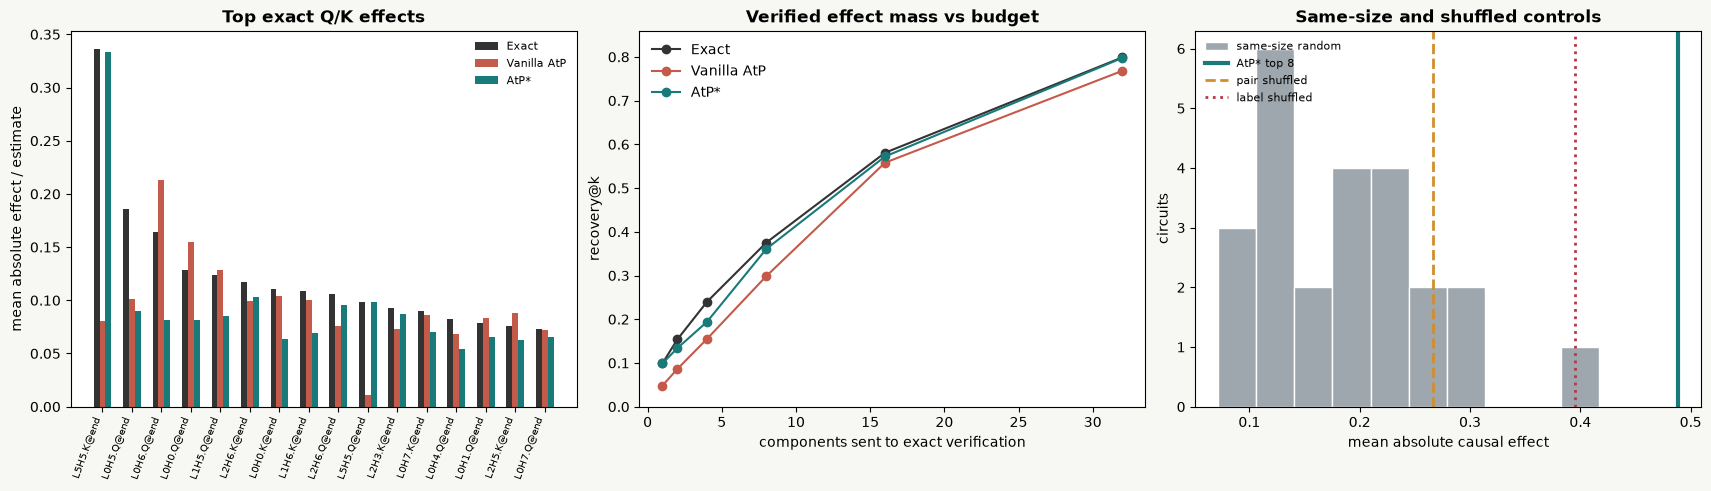

In [19]:
exact = real["exact_effects"]
vanilla = real["vanilla_atp"]
star = real["atp_star"]
exact_order = real["exact_ranking"]
top_show = exact_order[:16]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), constrained_layout=True)
fig.patch.set_facecolor("#f7f7f4")

x = np.arange(len(top_show))
axes[0].bar(x - 0.2, [exact[name] for name in top_show], 0.2, label="Exact", color="#333333")
axes[0].bar(x, [vanilla[name] for name in top_show], 0.2, label="Vanilla AtP", color="#c45a4a")
axes[0].bar(x + 0.2, [star[name] for name in top_show], 0.2, label="AtP*", color="#187a79")
axes[0].set_xticks(x, top_show, rotation=70, ha="right", fontsize=7)
axes[0].set_ylabel("mean absolute effect / estimate")
axes[0].set_title("Top exact Q/K effects", fontweight="bold")
axes[0].legend(frameon=False, fontsize=8)

for method, color in (("Exact", "#333333"), ("Vanilla AtP", "#c45a4a"), ("AtP*", "#187a79")):
    values = real["recovery_at_k"][method]
    axes[1].plot(list(values), list(values.values()), marker="o", label=method, color=color)
axes[1].set(xlabel="components sent to exact verification", ylabel="recovery@k", ylim=(0, 0.86))
axes[1].set_title("Verified effect mass vs budget", fontweight="bold")
axes[1].legend(frameon=False)

random_effects = real["same_size_random"]["random_effects"]
axes[2].hist(random_effects, bins=10, color="#9ea7ad", edgecolor="white", label="same-size random")
axes[2].axvline(real["same_size_random"]["discovered_effect"], color="#187a79", linewidth=3, label="AtP* top 8")
axes[2].axvline(real["control_effects"]["pair_shuffled"], color="#d28e2c", linestyle="--", linewidth=2, label="pair shuffled")
axes[2].axvline(real["control_effects"]["label_shuffled"], color="#b23a48", linestyle=":", linewidth=2, label="label shuffled")
axes[2].set_xlabel("mean absolute causal effect")
axes[2].set_ylabel("circuits")
axes[2].set_title("Same-size and shuffled controls", fontweight="bold")
axes[2].legend(frameon=False, fontsize=8)

real_asset = assets_dir / "atp_star_transformerlens_signature.png"
fig.savefig(real_asset, dpi=180, bbox_inches="tight", facecolor=fig.get_facecolor())
plt.show()

<details><summary>Interpretation - what the real result supports</summary>

- The behavior is real: the average clean-minus-corrupt logit-difference gap is about `8.40` across 24 examples.
- AtP* improves rank correlation with exhaustive Q/K patching from about `0.943` to `0.993`. It does not dominate vanilla AtP at every tiny `k`; read the computed recovery curve to identify the budgets at which each method wins.
- The top eight AtP* sites have causal effect about `0.489`, rank first against 24 reproducible same-size random circuits (random mean about `0.189`, best about `0.417`).
- A clean-to-clean pair-shuffled ranking and an independently label-shuffled ranking yield weaker true top-eight effects (about `0.266` and `0.395`). These are controls over ranking quality, not claims that those alternate metrics contain no grammatical information.
- Joint top-eight faithfulness is about `0.725` relative to patching all 96 candidate Q/K sites. This is useful screening, not a complete circuit.

</details>


The hook implementation now passes independent cross-layer derivative tests.
This corrected CPU run supersedes the earlier detached-node measurements.

## Try It Yourself - change the approximation budget

Choose **one** intervention before rerunning the cell:

1. Set `component_batch_size` to `1`, `4`, or `8`. Exact effects must stay fixed while wall time changes.
2. Change `top_k` from `8` to `4` or `16`. Compare recovery@k with joint faithfulness; they need not move together.
3. Remove `"cancellation"` from the toy GradDrop paths. Predict what happens to the cancel-source score before running.

exact unchanged: True
wall time (ms): 0.76
top-k: ('L0H0.Q@dest', 'L0H0.V@signal', 'L0H0.K@decoy', 'L0H0.K@signal')
cancel score: 0.0


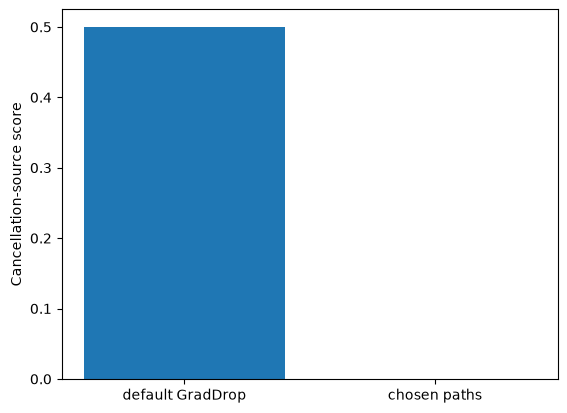

In [20]:
PLAY_BATCH_SIZE = 4
PLAY_TOP_K = 4
PLAY_GRAD_PATHS = ("attention", "linear")

play_exact, play_ms = timed(
    lambda: batched_exact_patch_effects(
        toy_model, clean_sites, corrupt_sites,
        component_batch_size=PLAY_BATCH_SIZE,
    )
)
play_star, _ = atp_star_scores(
    toy_model, clean_sites, corrupt_sites,
    grad_paths=PLAY_GRAD_PATHS,
)
play_ranking = rank_components(play_star)
print("exact unchanged:", max(abs(play_exact[name] - exact_effects[name]) for name in TOY_COMPONENTS) < 1e-12)
print("wall time (ms):", round(play_ms, 3))
print("top-k:", play_ranking[:PLAY_TOP_K])
print("cancel score:", play_star["L0M0.cancel_source"])

plt.bar(["default GradDrop", "chosen paths"], [atp_star_estimates["L0M0.cancel_source"], play_star["L0M0.cancel_source"]])
plt.ylabel("Cancellation-source score")
plt.show()

<details><summary>Interpretation</summary>

Batch size is a systems choice and must not change the oracle. Removing the one gradient control that breaks the direct/indirect cancellation makes the cancel-source estimate collapse again. This is why GradDrop is a structured sweep, not ordinary stochastic dropout.

</details>

## Bonus - anomaly hunting

Choose one investigation and write a prediction before coding:

1. Sweep the clean Q/K magnitude from `0.5` to `5.0`. At what saturation level does vanilla AtP's query rank collapse while the QK correction remains stable?
2. Change the nonlinear branch coefficient from `-0.5` to `-0.45` or `-0.55`. Plot exact, AtP, and GradDrop estimates as cancellation becomes imperfect.
3. Find the first `k` where the real AtP* recovery curve trails vanilla AtP, then inspect the exact and approximate scores of the components exchanged at that boundary.
4. Replace the clean-to-clean pair control with singular donors from a held-out noun set. Does the control become stronger because number information is restored?

<details><summary>What counts as a useful anomaly?</summary>

A useful anomaly changes a causal metric, identifies the components responsible, and survives a matched comparison. “The bars moved” is not enough. Record the prompt pairs, candidate set, exact effects, ranking change, and a control which should not move.

</details>

## Limitations

- The exact graph is a deliberately small scalar model organism. It proves the two estimator failure modes but is not a transformer.
- The real study scores final-position rotary queries and keys only. Values, head outputs, MLP neurons, and every token position are outside the candidate set.
- The real result uses Pythia-70M-deduped on a course-generated grammatical agreement task, not the paper's Pythia-12B CITY or IOI experiments.
- AtP* improves the overall real ranking but does not beat vanilla AtP at every small verification budget.
- The same-size null has 24 reproducible draws rather than exhaustive enumeration over `96 choose 8` sets.
- GradDrop reduces important false negatives; it does not guarantee none remain. The paper's subset-sampling confidence bound is a worthwhile extension, not claimed here.
- CPU execution validates the notebook and real result. The CUDA entry point is implemented but deliberately not run in this task.

## Reading Links

- [AtP*: An efficient and scalable method for localizing LLM behaviour to components](https://arxiv.org/abs/2403.00745)
- [Attribution Patching: Activation Patching at Industrial Scale](https://www.neelnanda.io/mechanistic-interpretability/attribution-patching)
- [Attribution Patching Outperforms Automated Circuit Discovery](https://arxiv.org/abs/2310.10348)
- Original ARENA [Indirect Object Identification](../../../chapter1_transformer_interp/instructions/pages/21_[1.4.1]_Indirect_Object_Identification.md)

## Consolidating Understanding

1. Activation patching is the causal oracle; AtP and AtP* propose an order for spending that oracle budget.
2. Vanilla AtP is a first-order Taylor estimate around the clean activation.
3. QK correction recomputes the nonlinear attention-pattern change and linearizes only downstream computation.
4. GradDrop preserves the clean forward pass while cutting one residual contribution's backward path.
5. Node scores and edge scores have different candidate sets and can expose different failures.
6. Recovery@k grades singleton ranking; joint faithfulness tests a selected circuit under simultaneous intervention.
7. Random, pair-shuffled, and label-shuffled controls are part of the evidence, not decoration.